# Лабораторная работа 1
## Сбор, визуализация и анализ данных по графу

Тема: финансовые временные ряды и алгоритмическая торговля.

В этой работе я рассматриваю научные статьи о прогнозировании финансовых рядов,
волатильности, торговых стратегиях и оптимизации портфеля. Мне интересно посмотреть,
какие направления можно выделить по текстам статей и как найти похожие публикации.
Для этого использую названия, авторов и аннотации статей arXiv с 2020 года.

Сначала собираю и проверяю данные, затем выделяю ключевые слова и строю два графа.
Один граф связывает понятия, другой связывает статьи. В конце сравниваю варианты поиска.

Весь код, настройки и сохранённые ответы API находятся в этом файле.
Для просмотра достаточно открыть notebook с готовыми результатами.
Для повторного выполнения нужны Python 3.12 и библиотеки из следующего блока.
Открывать другие файлы проекта не требуется.

## 1. Подготовка

Если библиотеки уже установлены, оставляю INSTALL_DEPENDENCIES выключенным.
Если окружение новое, включаю этот параметр, выполняю блок установки,
перезапускаю ядро и снова выполняю все ячейки с начала.
Установка библиотек и английской модели требует интернета.
Обычный расчёт на встроенных данных работает без интернета.

In [1]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    import subprocess
    import sys
    packages = [
        'numpy==2.5.3', 'pandas==3.0.6', 'scipy==1.18.1',
        'scikit-learn==1.9.1', 'networkx==3.7', 'spacy==3.8.16',
        'matplotlib==3.11.2', 'seaborn==0.13.2', 'requests==2.34.2',
        'ipywidgets==8.1.9',
        'https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl'
    ]
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *packages])
    print('Установка завершена. Перезапустите ядро и отключите установку.')

In [2]:
%matplotlib inline
import base64
import gzip
import hashlib
import json
import math
import platform
import random
import re
import time
from collections import Counter, defaultdict
from datetime import datetime, timezone, timedelta
from importlib.metadata import version
from xml.etree import ElementTree as ET

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import spacy
import ipywidgets as widgets
from matplotlib.patches import Patch
from scipy.sparse import csr_matrix, triu
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import adjusted_rand_score
from IPython.display import display, Markdown, HTML

def digest(body):
    return hashlib.sha256(body).hexdigest()

def plain(value):
    text = str(value)
    for old, new in {chr(8212): '-', chr(8211): '-', chr(8594): ' -> ', chr(8805): '>=', chr(8776): 'около '}.items():
        text = text.replace(old, new)
    return re.sub(r'\$[^$]*\$', '[обозначение из статьи]', text)

def show_table(frame):
    frame = frame.copy()
    for column in frame.columns:
        frame[column] = frame[column].map(lambda v: plain(v) if isinstance(v, str) else v)
    display(frame)

def show_figure(fig):
    display(fig)
    plt.close(fig)

pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_rows', 30)
sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 120, 'axes.titlesize': 13, 'axes.labelsize': 11})
display(HTML('<style>.dataframe td,.dataframe th{text-align:left!important;white-space:normal;max-width:300px;overflow-wrap:anywhere}</style>'))
versions = {name: version(name) for name in ['numpy','pandas','scipy','scikit-learn','networkx','spacy','en-core-web-sm','matplotlib']}
show_table(pd.DataFrame(versions.items(), columns=['Библиотека','Версия']))
print('Python:', platform.python_version())

,Библиотека,Версия
0,numpy,2.5.3
1,pandas,3.0.6
2,scipy,1.18.1
3,scikit-learn,1.9.1
4,networkx,3.7
5,spacy,3.8.16
6,en-core-web-sm,3.8.0
7,matplotlib,3.11.2


Python: 3.12.2


In [3]:
cfg = {'schema_version': '1.0', 'seed': 42, 'collection': {'endpoint': 'https://export.arxiv.org/api/query', 'date_start': '2020-01-01', 'date_end': '2026-10-04', 'min_papers': 300, 'target_papers': 500, 'page_size': 100, 'per_query_year_limit': 40, 'interval': 3.1, 'timeout': 45, 'retries': 3, 'queries': {'Q1': '(cat:q-fin.ST OR ti:"financial time series" OR abs:"stock price prediction" OR abs:"stock return prediction")', 'Q2': '((ti:volatility OR abs:"volatility forecasting" OR abs:"volatility prediction") AND (cat:q-fin.RM OR cat:q-fin.ST OR abs:financial OR abs:stock))', 'Q3': '(cat:q-fin.TR OR ti:"algorithmic trading" OR abs:"algorithmic trading" OR (abs:"reinforcement learning" AND abs:trading))', 'Q4': '(cat:q-fin.PM OR ti:"portfolio optimization" OR abs:"portfolio optimization" OR ti:"asset allocation")'}}, 'preprocessing': {'model': 'en_core_web_sm'}, 'keywords': {'min_df': 2, 'max_df': 0.8, 'title_weight': 2, 'abstract_weight': 1, 'top_k': 12, 'ngram_max': 3, 'phrase_bonus': 0.2}, 'analysis': {'resolution': 1.0, 'seeds': [42, 43, 44], 'resolutions': [0.5, 1.0, 1.5], 'keyword_counts': [8, 12, 16], 'eigenvector_max_iter': 1000, 'eigenvector_tol': 1e-06}, 'search': {'top_k': 5, 'alpha': 0.85, 'max_iter': 1000, 'tol': 1e-10}, 'visualization': {'max_nodes': 90, 'max_labels': 22}}

EXTRA_STOPWORDS = ['paper', 'propose', 'proposed', 'result', 'show', 'study', 'present', 'approach', 'method', 'use', 'using', 'used', 'consider', 'provide', 'demonstrate', 'experiment', 'experimental', 'performance', 'novel', 'new', 'based', 'obtain', 'work', 'research', 'however', 'also', 'et', 'al']
ALIASES = {'stock markets': 'stock market', 'financial markets': 'financial market', 'time series': 'time series', 'neural networks': 'neural network', 'reinforcement learning': 'reinforcement learning', 'portfolio optimisation': 'portfolio optimization', 'optimisation': 'optimization', 'modelling': 'modeling', 'forecast': 'forecasting', 'forecasts': 'forecasting', 'forecasting': 'forecasting', 'cryptocurrencie': 'cryptocurrency', 'cryptocurrencies': 'cryptocurrency', 'models': 'model', 'markets': 'market', 'networks': 'network', 'datum': 'data'}
TOPIC_OVERRIDES = {'exclude': {'2002.07100': 'Международная товарная торговля и GDP, без задачи финансовых активов.', '2002.07408': 'Аукционы рекламных показов, а не финансовая торговля.', '2201.02397': 'Калибровка страховых контрактов жизни, без рыночных рядов или инвестиционного портфеля.', '2202.07128': 'Концептуальная маркетинговая гипотеза co-branding; нет анализа рядов или торгового решения.', '2203.12395': 'Цены овощей для фермеров, не финансовые активы.', '2302.00797': 'Переговорные игры с людьми, без финансового применения.', '2302.06092': 'Управление солнечными UAV; trade-off ошибочно сработал как trading.', '2401.11759': 'Ресурсы sensing/communication/computing в автомобильной сети.', '2401.13947': 'Физическая энергосеть и распределение энергии между prosumers.', '2402.01802': 'Торговля моделями federated learning, не активами.', '2402.04533': 'Хранение транзакций и стабильность вознаграждений майнеров, а не финансовые ряды.', '2501.04964': 'Бытовое энергопотребление и shared energy storage.', '2501.10535': 'Прогноз бронирований Airbnb, не финансовые активы.', '2501.16591': 'Прогноз мощности ветровых турбин, без задачи финансового рынка.', '2603.02898': 'Цены еды и гуманитарные риски, не финансовые активы.', '2604.04529': 'Макроэкономические панели FRED-QD; нет конкретной задачи рыночного прогноза.'}}

random.seed(cfg['seed'])
np.random.seed(cfg['seed'])
print('Начальная дата:', cfg['collection']['date_start'])
print('Конечная дата:', cfg['collection']['date_end'])
print('Число тегов на статью:', cfg['keywords']['top_k'])
print('Seed:', cfg['seed'])

Начальная дата: 2020-01-01
Конечная дата: 2026-10-04
Число тегов на статью: 12
Seed: 42


## 2. Загрузка данных из arXiv

Я использую API arXiv, который возвращает метаданные в XML.
Делаю четыре вида запросов: финансовые ряды, волатильность, торговля и портфель.
Каждый вид запроса выполняется отдельно для каждого года с 2020 по 2026.
Дата окончания выборки зафиксирована на 4 октября 2026 года.
Беру первые 40 результатов каждого запроса и года по дате первой публикации.
Это ограниченная выборка, поэтому по числу статей нельзя судить обо всём arXiv.

Внутри следующей ячейки находятся сохранённые ответы настоящих запросов API.
Они сжаты, чтобы данные занимали меньше места. Ячейку с длинной строкой можно свернуть.
Сжатие не меняет исходные названия, авторов и аннотации.
При повторном запуске ответы распаковываются в память.

Чтобы заново скачать данные, ниже можно поставить DOWNLOAD_DATA = True.
Тогда клиент последовательно отправит запросы с паузой не меньше трёх секунд.
При DOWNLOAD_DATA = False используются встроенные ответы, а не сеть.
После обновления данных заново выполняются все следующие разделы.

In [4]:
EMBEDDED_DATA = (
    '...'
    '/6sK/MnP/l924Zjx26wmAA=='
)
assert digest(base64.b64decode(EMBEDDED_DATA)) == 'b5e530942a615bafcbee1a6ac33b07b4ee03e6c8009738d499e36a8bc3345c84'

saved = json.loads(gzip.decompress(base64.b64decode(EMBEDDED_DATA)))
api_cache = saved['responses']
print('Встроенных ответов API:', len(api_cache))

Встроенных ответов API: 28


In [5]:
NS = {'a': 'http://www.w3.org/2005/Atom', 'o': 'http://a9.com/-/spec/opensearch/1.1/', 'x': 'http://arxiv.org/schemas/atom'}

def canonical_id(value):
    value = str(value).strip().split('?')[0].rstrip('/')
    value = re.sub('^https?://(?:export\\.)?arxiv\\.org/(?:abs|pdf)/', '', value)
    return re.sub('v\\d+$', '', re.sub('\\.pdf$', '', value))

def parse_atom(body):
    feed = ET.fromstring(body)
    if feed.tag != '{http://www.w3.org/2005/Atom}feed':
        raise ValueError('Expected an Atom feed, not an HTML response')
    total_text = feed.findtext('o:totalResults', namespaces=NS)
    if total_text is None:
        raise ValueError('Missing totalResults')
    records = []
    for entry in feed.findall('a:entry', NS):
        get = lambda field: entry.findtext(f'a:{field}', default='', namespaces=NS)
        url = get('id')
        if '/api/errors' in url or get('title').strip() == 'Error':
            raise ValueError(get('summary'))
        if '/abs/' not in url:
            raise ValueError('Missing article identifier')
        versioned = url.split('/abs/', 1)[1]
        primary = entry.find('x:primary_category', NS)
        records.append({'schema_version': '1.0', 'paper_id': canonical_id(url), 'versioned_id': versioned, 'title': ' '.join(get('title').split()), 'abstract': ' '.join(get('summary').split()), 'authors': [e.text or '' for e in entry.findall('a:author/a:name', NS)], 'published': get('published'), 'updated': get('updated'), 'categories': sorted({e.attrib['term'] for e in entry.findall('a:category', NS)}), 'primary_category': primary.attrib.get('term', '') if primary is not None else '', 'abstract_url': f'https://arxiv.org/abs/{versioned}'})
    return (records, int(total_text))

def merge_records(records):
    groups = defaultdict(list)
    for r in records:
        groups[r['paper_id']].append(r)
    merged = []
    for pid, group in sorted(groups.items()):

        def key(r):
            m = re.search('v(\\d+)$', r['versioned_id'])
            return (int(m.group(1)) if m else 0, r['updated'], r['source_request_ids'][0])
        chosen = dict(max(group, key=key))
        chosen['source_query_ids'] = sorted({i for r in group for i in r['source_query_ids']})
        chosen['source_request_ids'] = sorted({i for r in group for i in r['source_request_ids']})
        chosen['retrieved_versions'] = sorted({r['versioned_id'] for r in group})
        merged.append(chosen)
    return merged

def relevance(record):
    text = (record['title'] + ' ' + record['abstract']).lower()
    strong = ['portfolio', 'asset allocation', 'stock', 'equity', 'equities', 'financial market', 'financial time', 'trading', 'volatility', 'limit order', 'market microstructure', 'cryptocurrency', 'bitcoin', 'foreign exchange', 'futures market', 'investment']
    matched = [term for term in strong if term in text]
    if not matched:
        return (False, 'outside_topic', [])
    cats = record['categories']
    financial = any((c.startswith('q-fin.') for c in cats)) or any((t in text for t in ['financial', 'stock', 'asset', 'investment', 'trading', 'bitcoin', 'cryptocurrency']))
    if not financial:
        return (False, 'outside_topic', matched)
    return (True, 'included_topic_rule', matched)

def select_corpus(records, cfg, seed=42, overrides=None):
    start = datetime.fromisoformat(cfg['date_start']).replace(tzinfo=timezone.utc)
    end = datetime.fromisoformat(cfg['date_end']).replace(tzinfo=timezone.utc) + timedelta(days=1)
    eligible, decisions = ([], {})
    for r in records:
        try:
            date = datetime.fromisoformat(r['published'].replace('Z', '+00:00'))
            valid_date = date.tzinfo is not None and start <= date < end
        except (ValueError, TypeError):
            valid_date = False
        reason = 'outside_date_window' if not valid_date else None
        if reason is None and (not r['title'] or not r['abstract'] or (not r['authors']) or any((not a for a in r['authors']))):
            reason = 'missing_metadata'
        keep, topical_reason, signals = relevance(r)
        if reason is None and (not keep):
            reason = topical_reason
        excluded = (overrides or {}).get('exclude', {})
        if r['paper_id'] in excluded:
            reason = 'outside_topic_audited'
        decisions[r['paper_id']] = {'paper_id': r['paper_id'], 'included': reason is None, 'reason_code': reason or 'included_topic_rule', 'reason_text': ', '.join(signals)}
        if r['paper_id'] in excluded:
            decisions[r['paper_id']].update(reason_text=excluded[r['paper_id']])
        if reason is None:
            eligible.append(r)
    if len(eligible) < cfg['min_papers']:
        raise ValueError(f'Only {len(eligible)} eligible papers; need {cfg['min_papers']}')
    target = min(cfg['target_papers'], len(eligible))
    groups = defaultdict(list)
    for r in eligible:
        groups[r['published'][:4]].append(r)
    quotas = {year: target * len(rows) / len(eligible) for year, rows in groups.items()}
    allocation = {year: int(q) for year, q in quotas.items()}
    order = sorted(groups, key=lambda y: (-(quotas[y] - allocation[y]), y))
    for year in order[:target - sum(allocation.values())]:
        allocation[year] += 1
    rng, chosen = (random.Random(seed), [])
    for year in sorted(groups):
        rows = sorted(groups[year], key=lambda r: r['paper_id'])
        rng.shuffle(rows)
        chosen.extend(rows[:allocation[year]])
        for r in rows[allocation[year]:]:
            decisions[r['paper_id']].update(included=False, reason_code='not_sampled')
    return (sorted(chosen, key=lambda r: r['paper_id']), list(decisions.values()))

In [6]:
class ArxivClient:
    def __init__(self, settings, cache, download=False):
        self.settings = settings
        self.cache = cache
        self.download = download
        self.last_request = 0.0
        self.session = requests.Session()
        self.session.headers['User-Agent'] = 'student-market-research/1.0 (educational metadata analysis)'

    def page(self, query, query_id, year, start, limit):
        params = {'search_query': query, 'start': start, 'max_results': limit,
                  'sortBy': 'submittedDate', 'sortOrder': 'ascending'}
        request_id = digest(json.dumps(params, sort_keys=True).encode())[:20]
        if not self.download:
            if request_id not in self.cache:
                raise ValueError('Запроса нет во встроенных данных. Включите DOWNLOAD_DATA.')
            item = self.cache[request_id]
            body = item['body'].encode('utf-8')
            metadata = item['metadata']
            assert digest(body) == metadata['sha256'], 'Повреждён встроенный ответ API'
        else:
            for attempt in range(self.settings['retries'] + 1):
                pause = self.settings['interval'] - (time.monotonic() - self.last_request)
                time.sleep(max(0, pause))
                self.last_request = time.monotonic()
                response = None
                try:
                    response = self.session.get(self.settings['endpoint'], params=params, timeout=self.settings['timeout'])
                    response.raise_for_status()
                    body = response.content
                    parse_atom(body)
                    break
                except (requests.RequestException, ET.ParseError, ValueError) as error:
                    if attempt == self.settings['retries']:
                        raise RuntimeError(f'Не удалось получить {query_id}/{year}: {error}') from error
                    retry_after = response.headers.get('Retry-After', '0') if response is not None else '0'
                    try:
                        retry_after = float(retry_after)
                    except ValueError:
                        retry_after = 0
                    time.sleep(max(3 * 2 ** attempt, retry_after))
            metadata = {'request_id': request_id, 'query_id': query_id, 'year': year,
                        'params': params, 'url': response.url,
                        'collected_at': datetime.now(timezone.utc).isoformat(), 'sha256': digest(body)}
            self.cache[request_id] = {'body': body.decode('utf-8'), 'metadata': metadata}
        rows, total = parse_atom(body)
        for row in rows:
            row.update(snapshot_id='notebook_snapshot', collected_at=metadata['collected_at'],
                       source_query_ids=[query_id], source_request_ids=[request_id])
        return rows, total

def download_arxiv(settings, cache, download=False):
    client = ArxivClient(settings, cache, download)
    retrieved, coverage = [], []
    for year in range(int(settings['date_start'][:4]), int(settings['date_end'][:4]) + 1):
        low = max(settings['date_start'], f'{year}-01-01').replace('-', '') + '0000'
        high = min(settings['date_end'], f'{year}-12-31').replace('-', '') + '2359'
        for query_id, expression in settings['queries'].items():
            query = f'{expression} AND submittedDate:[{low} TO {high}]'
            count = 0
            for offset in range(0, settings['per_query_year_limit'], settings['page_size']):
                limit = min(settings['page_size'], settings['per_query_year_limit'] - offset)
                rows, total = client.page(query, query_id, year, offset, limit)
                retrieved.extend(rows)
                count += len(rows)
                if len(rows) < limit or offset + len(rows) >= total:
                    break
            coverage.append({'Запрос': query_id, 'Год': year, 'Всего в API': total, 'Получено': count})
            print(f'{query_id}/{year}: получено {count} из {total}')
    client.session.close()
    return retrieved, coverage

DOWNLOAD_DATA = False
active_cache = {key: dict(value) for key, value in api_cache.items()}
retrieved, coverage = download_arxiv(cfg['collection'], active_cache, DOWNLOAD_DATA)
show_table(pd.DataFrame(cfg['collection']['queries'].items(), columns=['Запрос','Выражение']))
show_table(pd.DataFrame(coverage))

Q1/2020: получено 40 из 299
Q2/2020: получено 40 из 42
Q3/2020: получено 40 из 247
Q4/2020: получено 40 из 197
Q1/2021: получено 40 из 276
Q2/2021: получено 40 из 52
Q3/2021: получено 40 из 281
Q4/2021: получено 40 из 203
Q1/2022: получено 40 из 250
Q2/2022: получено 40 из 65
Q3/2022: получено 40 из 279
Q4/2022: получено 40 из 193
Q1/2023: получено 40 из 319
Q2/2023: получено 40 из 57
Q3/2023: получено 40 из 338
Q4/2023: получено 40 из 263
Q1/2024: получено 40 из 359
Q2/2024: получено 40 из 71
Q3/2024: получено 40 из 396
Q4/2024: получено 40 из 279
Q1/2025: получено 40 из 346
Q2/2025: получено 40 из 97
Q3/2025: получено 40 из 761
Q4/2025: получено 40 из 355
Q1/2026: получено 40 из 353
Q2/2026: получено 40 из 85
Q3/2026: получено 40 из 885
Q4/2026: получено 40 из 360


,Запрос,Выражение
0,Q1,"(cat:q-fin.ST OR ti:""financial time series"" OR abs:""stock price prediction"" OR abs:""stock return..."
1,Q2,"((ti:volatility OR abs:""volatility forecasting"" OR abs:""volatility prediction"") AND (cat:q-fin.R..."
2,Q3,"(cat:q-fin.TR OR ti:""algorithmic trading"" OR abs:""algorithmic trading"" OR (abs:""reinforcement le..."
3,Q4,"(cat:q-fin.PM OR ti:""portfolio optimization"" OR abs:""portfolio optimization"" OR ti:""asset alloca..."


,Запрос,Год,Всего в API,Получено
0,Q1,2020,299,40
1,Q2,2020,42,40
2,Q3,2020,247,40
3,Q4,2020,197,40
4,Q1,2021,276,40
5,Q2,2021,52,40
6,Q3,2021,281,40
7,Q4,2021,203,40
8,Q1,2022,250,40
9,Q2,2022,65,40


## 3. Очистка и отбор статей

Одна статья может попасть в несколько запросов. Сначала объединяю такие записи по ID.
Версии одной статьи не считаю отдельными публикациями.
Затем проверяю дату первой публикации, заполненность полей и связь с финансовой темой.
Дата обновления статьи не используется для проверки её возраста.

Часть записей со словом trading относится к рекламе или обмену моделями.
Для таких исключений в настройках оставлены конкретные ID и причины.
Из подходящих записей выбираю 500 статей с сохранением долей по годам.
Если подходит меньше 500, беру все, но требую не меньше 300.
Следующие разделы используют именно список papers, полученный в этой ячейке.

In [7]:
candidates = merge_records(retrieved)
papers, selection = select_corpus(candidates, cfg['collection'], cfg['seed'], TOPIC_OVERRIDES)
if not DOWNLOAD_DATA:
    for paper in papers:
        paper['snapshot_id'] = 'arxiv_2026-10-04'

corpus_sha256 = digest(json.dumps(papers, ensure_ascii=False, sort_keys=True).encode())
same_corpus = corpus_sha256 == saved['corpus_sha256']
if not DOWNLOAD_DATA:
    assert same_corpus, 'Отбор встроенных статей изменился'

assert len(papers) >= cfg['collection']['min_papers']
assert len({p['paper_id'] for p in papers}) == len(papers)
assert all(p['title'] and p['abstract'] and p['authors'] for p in papers)
assert all(cfg['collection']['date_start'] <= p['published'][:10] <= cfg['collection']['date_end'] for p in papers)
show_table(pd.DataFrame([{'Получено записей': len(retrieved), 'Без повторов': len(candidates),
                         'Повторные записи': len(retrieved)-len(candidates), 'Выбрано статей': len(papers)}]))
show_table(pd.DataFrame(Counter(r['reason_code'] for r in selection).items(), columns=['Причина отбора','Число']))
show_table(pd.DataFrame(papers)[['paper_id','title','authors','published']].head())
for paper in papers[:2]:
    print('\nСтатья:', paper['paper_id'], plain(paper['title']))
    print('Аннотация:', plain(paper['abstract']))
print('\nПроверка корпуса пройдена.')

,Получено записей,Без повторов,Повторные записи,Выбрано статей
0,1120,1043,77,500


,Причина отбора,Число
0,not_sampled,316
1,included_topic_rule,500
2,outside_topic,211
3,outside_topic_audited,16


,paper_id,title,authors,published
0,2001.01518,Disentangling shock diffusion on complex networks: Identification through graph planarity,"[Sudarshan Kumar, Tiziana Di Matteo, Anindya S. Chakrabarti]",2020-01-06T12:25:58Z
1,2001.01612,A Note on Portfolio Optimization with Quadratic Transaction Costs,"[Pierre Chen, Edmond Lezmi, Thierry Roncalli, Jiali Xu]",2020-01-06T14:52:17Z
2,2001.02966,Clustering Approaches for Global Minimum Variance Portfolio,[Jinwoo Park],2020-01-09T13:27:40Z
3,2001.03333,A new approach for trading based on Long Short Term Memory technique,"[Zineb Lanbouri, Saaid Achchab]",2020-01-10T07:56:30Z
4,2001.04185,Zooming In on Equity Factor Crowding,"[Valerio Volpati, Michael Benzaquen, Zoltan Eisler, Iacopo Mastromatteo, Bence Toth, Jean-Philip...",2020-01-13T12:34:45Z



Статья: 2001.01518 Disentangling shock diffusion on complex networks: Identification through graph planarity
Аннотация: Large scale networks delineating collective dynamics often exhibit cascading failures across nodes leading to a system-wide collapse. Prominent examples of such phenomena would include collapse on financial and economic networks. Intertwined nature of the dynamics of nodes in such network makes it difficult to disentangle the source and destination of a shock that percolates through the network, a property known as reflexivity. In this article, a novel methodology is proposed which combines vector autoregression model with an unique identification restrictions obtained from the topological structure of the network to uniquely characterize cascades. In particular, we show that planarity of the network allows us to statistically estimate a dynamical process consistent with the observed network and thereby uniquely identify a path for shock propagation from any chosen e

## 4. Обработка текста

Статьи написаны на английском, поэтому использую английскую модель spaCy.
Слова привожу к нижнему регистру и начальной форме. Например, prices становится price.
Так разные формы одного слова не создают лишние отдельные узлы.
Некоторые варианты написания объединяю с помощью небольшого словаря.

Для ключевых слов убираю служебные слова и слишком общие слова вроде method.
Рассматриваю отдельные слова, сочетания из двух слов и сочетания из трёх слов.
Фраза должна состоять из соседних слов исходного предложения и заканчиваться существительным.
Через удалённые слова, знаки препинания и границы предложений фразы не склеиваю.
Для каждого кандидата сохраняю исходный фрагмент текста.

Для проверки закона Ципфа отдельно сохраняю слова вместе со служебными словами.
Там важно обычное распределение всех слов, а не только тематические теги.

In [8]:
class TextProcessor:
    GENERIC_UNIGRAMS = {'data', 'model', 'models', 'method', 'approach', 'framework', 'case', 'result', 'analysis', 'problem', 'technique', 'number', 'size', 'note', 'reason', 'issue', 'aim', 'setting', 'example', 'application', 'procedure', 'advantage', 'performance'}

    def __init__(self, settings, extra_stopwords, aliases):
        try:
            self.nlp = spacy.load(settings['model'], disable=['ner'])
        except OSError as error:
            raise RuntimeError('Не установлена английская модель. Включите установку в разделе 1 и перезапустите ядро.') from error
        self.stopwords = set(self.nlp.Defaults.stop_words) | set(extra_stopwords)
        self.aliases = dict(aliases)

    def lemma(self, token):
        lemma = token.lemma_.lower().strip()
        return self.aliases.get(lemma, lemma)

    def extract_doc(self, doc, field, ngram_max=3):
        counts, evidence = (Counter(), defaultdict(list))
        zipf_tokens, content_tokens = ([], [])
        for token in doc:
            if token.is_alpha:
                lemma = self.lemma(token)
                if lemma:
                    zipf_tokens.append(lemma)
                    if lemma not in self.stopwords and len(lemma) >= 2:
                        content_tokens.append(lemma)
        for sentence in doc.sents:
            blocks, block = ([], [])
            for token in sentence:
                lemma = self.lemma(token)
                valid = token.is_alpha and re.fullmatch('[a-z]+', lemma) and (len(lemma) >= 2) and (lemma not in self.stopwords) and (field == 'query' or token.pos_ in {'NOUN', 'PROPN', 'ADJ'})
                if valid:
                    block.append((lemma, token.idx, token.idx + len(token.text), token.pos_))
                elif block:
                    blocks.append(block)
                    block = []
            if block:
                blocks.append(block)
            for block in blocks:
                for n in range(1, ngram_max + 1):
                    for i in range(len(block) - n + 1):
                        span = block[i:i + n]
                        if field != 'query' and span[-1][3] not in {'NOUN', 'PROPN'}:
                            continue
                        if n == 1 and span[0][0] in self.GENERIC_UNIGRAMS:
                            continue
                        term = ' '.join((t[0] for t in span))
                        term = self.aliases.get(term, term)
                        counts[term] += 1
                        if len(evidence[term]) < 3:
                            start, end = (span[0][1], span[-1][2])
                            evidence[term].append({'field': field, 'start': start, 'end': end, 'text': doc.text[start:end]})
        return {'counts': dict(counts), 'evidence': dict(evidence), 'zipf_tokens': zipf_tokens, 'content_tokens': content_tokens}

    def process(self, papers, ngram_max=3):
        texts = [r[field] for r in papers for field in ('title', 'abstract')]
        docs = iter(self.nlp.pipe(texts, batch_size=32))
        rows = []
        for paper in papers:
            rows.append({'paper_id': paper['paper_id'], 'title': self.extract_doc(next(docs), 'title', ngram_max), 'abstract': self.extract_doc(next(docs), 'abstract', ngram_max)})
        return rows

    def query_terms(self, query, vocabulary):
        data = self.extract_doc(self.nlp(query), 'query')
        matched = sorted(set(data['counts']) & set(vocabulary))
        return [term for term in matched if not any((term != other and subphrase(term, other) for other in matched))]

processor = TextProcessor(cfg['preprocessing'], EXTRA_STOPWORDS, ALIASES)
started = time.monotonic()
texts = processor.process(papers, cfg['keywords']['ngram_max'])
print('Обработано статей:', len(texts))
print('Время обработки, секунд:', round(time.monotonic() - started, 1))
example = texts[0]
print('Первые слова аннотации:', ', '.join(example['abstract']['content_tokens'][:25]))

Обработано статей: 500
Время обработки, секунд: 6.5
Первые слова аннотации: large, scale, network, delineate, collective, dynamic, exhibit, cascade, failure, node, lead, system, wide, collapse, prominent, example, phenomenon, include, collapse, financial, economic, network, intertwine, nature, dynamic


## 5. Разведочный анализ и закон Ципфа

Сначала смотрю распределение статей по годам и основным категориям.
Затем сравниваю длину названий, длину аннотаций и число авторов.
Эти графики помогают понять состав корпуса и заметить необычные записи.
2026 год в выборке неполный. Из-за ограничений запросов распределение по годам
описывает только собранный корпус.

In [9]:
def corpus_figures(papers, texts):
    years = Counter((p['published'][:4] for p in papers))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
    axes[0].bar(list(sorted(years)), [years[y] for y in sorted(years)], color='#3567a8')
    axes[0].set(title='Статьи по годам: состав выборки', xlabel='Год первой публикации', ylabel='Число статей')
    categories = Counter((p['primary_category'] for p in papers))
    top = categories.most_common(8)
    axes[1].barh([t[0] for t in top][::-1], [t[1] for t in top][::-1], color='#2b8b7e')
    axes[1].set(title='Основная категория arXiv', xlabel='Число статей')
    yield ('corpus', fig)
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout='constrained')
    for ax, field, label in [(axes[0], 'title', 'Название'), (axes[1], 'abstract', 'Аннотация')]:
        values = [len(t[field]['zipf_tokens']) for t in texts]
        ax.hist(values, bins=25, color='#3567a8', alpha=0.85)
        ax.set(title=label, xlabel='Количество слов', ylabel='Число статей')
    axes[2].hist([len(p['authors']) for p in papers], bins=20, color='#2b8b7e')
    axes[2].set(title='Авторы', xlabel='Число авторов', ylabel='Число статей')
    yield ('lengths', fig)

def zipf_figure(frame, metrics):
    fig, ax = plt.subplots(figsize=(10, 5), layout='constrained')
    ax.loglog(frame['rank'], frame['frequency'], '.', ms=3, alpha=0.65, label='Униграммы, стоп-слова сохранены')
    if metrics['status'] == 'ok':
        x = np.arange(metrics['rank_min'], metrics['rank_max'] + 1)
        ax.loglog(x, np.exp(metrics['intercept']) * x ** (-metrics['s']), color='#ca563b', lw=2, label=f'Аппроксимация: s={metrics['s']:.3f}')
    ax.set(xlabel='Ранг слова', ylabel='Частота', title='Закон Ципфа: частота-ранг (log-log)')
    ax.legend()
    return fig

def keyword_figures(keywords):
    counts = Counter((t['term_id'] for r in keywords for t in r['keywords']))
    top = counts.most_common(20)
    fig, axes = plt.subplots(1, 3, figsize=(17, 7), layout='constrained')
    axes[0].barh([t[0] for t in top][::-1], [t[1] for t in top][::-1], color='#3567a8')
    axes[0].set(title='20 самых распространённых тегов', xlabel='Число статей с выбранным тегом')
    ngrams = Counter((t['ngram_size'] for r in keywords for t in r['keywords']))
    axes[1].bar([str(i) for i in sorted(ngrams)], [ngrams[i] for i in sorted(ngrams)], color='#2b8b7e')
    axes[1].set(title='Длина выбранных терминов', xlabel='Число слов в термине', ylabel='Число тегов в корпусе')
    sizes = Counter((len(r['keywords']) for r in keywords))
    axes[2].bar([str(n) for n in sorted(sizes)], [sizes[n] for n in sorted(sizes)], color='#ca563b')
    axes[2].set(title='Теги на одну статью', xlabel='Количество выбранных тегов', ylabel='Число статей')
    return fig

def graph_figure(graph, communities=None, max_nodes=90, max_labels=22, seed=42, title='Граф', node_names=None):
    selected = sorted(graph, key=lambda n: (-graph.degree(n, weight='weight'), str(n)))[:max_nodes]
    view = graph.subgraph(selected).copy()
    threshold = 1
    view.remove_edges_from([(a, b) for a, b, d in view.edges(data=True) if d['weight'] < threshold])
    positions = nx.spring_layout(view, seed=seed, weight='weight', k=1.8 / math.sqrt(max(1, len(view))), iterations=100)
    membership = {n: i for i, g in enumerate(communities or []) for n in g}
    palette = sns.color_palette('husl', max(1, len(communities or [])))
    colors = [palette[membership[n]] if n in membership else '#407cad' for n in view]
    strength = dict(graph.degree(weight='weight'))
    maximum = max((strength[n] for n in view), default=1)
    sizes = [80 + 750 * strength[n] / max(1, maximum) for n in view]
    fig, ax = plt.subplots(figsize=(13, 9), layout='constrained')
    nx.draw_networkx_edges(view, positions, ax=ax, alpha=0.38, width=0.9, edge_color='#607d96')
    nx.draw_networkx_nodes(view, positions, ax=ax, node_color=colors, node_size=sizes, edgecolors='white', linewidths=0.6)
    labels = {n: (node_names or {}).get(n, str(n)) for n in selected[:min(max_labels, 14)]}
    artists = nx.draw_networkx_labels(view, positions, labels, ax=ax, font_size=9, bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85, 'pad': 1})
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    boxes = []
    for artist in artists.values():
        for _ in range(18):
            box = artist.get_window_extent(renderer).expanded(1.03, 1.15)
            if not any((box.overlaps(previous) for previous in boxes)):
                break
            x, y = artist.get_position()
            artist.set_position((x, y + 0.035))
        boxes.append(artist.get_window_extent(renderer).expanded(1.03, 1.15))
    ax.set_title(f'{title}\nПоказано {len(view)} из {len(graph)} узлов; рёбра рисунка: вес >= {threshold}')
    ax.axis('off')
    ax.text(0.01, 0.01, 'Размер узла - strength полного графа; фильтр относится только к рисунку.', transform=ax.transAxes, fontsize=9)
    if communities:
        shown = sorted({membership[n] for n in view if n in membership})
        ax.legend(handles=[Patch(color=palette[i], label=str(i)) for i in shown], title='ID сообщества', loc='upper left', bbox_to_anchor=(1.0, 1.0), ncol=2, fontsize=8, title_fontsize=9, frameon=False)
    return fig

def centrality_figure(rows):
    frame = pd.DataFrame(rows)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), layout='constrained')
    for ax, metric in zip(axes.flat, ['degree', 'betweenness', 'closeness', 'eigenvector']):
        top = frame.dropna(subset=[metric]).sort_values([metric, 'term_id'], ascending=[False, True]).head(10).iloc[::-1]
        ax.barh(top['term_id'], top[metric], color='#3567a8')
        ax.set(title=metric, xlabel='Значение меры')
    return fig

def local_search_figure(graph, response):
    paths = [r['path'] for r in response['results']]
    selected = set(response['seed_ids'][:1]) | {n for path in paths for n in path}
    view = nx.Graph()
    view.add_nodes_from(sorted(selected))
    for path in paths:
        for a, b in zip(path, path[1:]):
            view.add_edge(a, b, **graph[a][b])
    pos = nx.spring_layout(view, seed=42, weight='weight', iterations=100)
    fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
    colors = ['#ca563b' if n in response['seed_ids'] else '#3567a8' for n in view]
    labels = {n: n.replace('.', '.\n') for n in view}
    nx.draw_networkx(view, pos, ax=ax, labels=labels, node_color=colors, node_size=1800, font_size=9, font_color='white', edge_color='#607d96')
    nx.draw_networkx_edge_labels(view, pos, {(a, b): d['weight'] for a, b, d in view.edges(data=True)}, ax=ax, font_size=9)
    ax.set_title('Объясняющие пути выдачи: seed красный, вес - общие теги')
    ax.axis('off')
    return fig

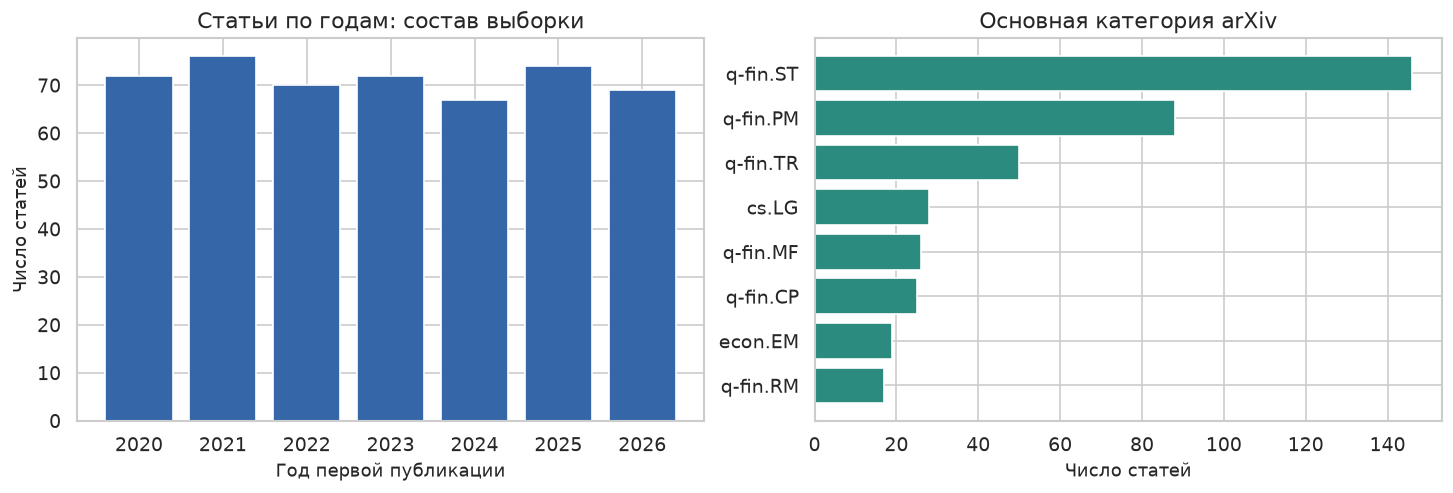

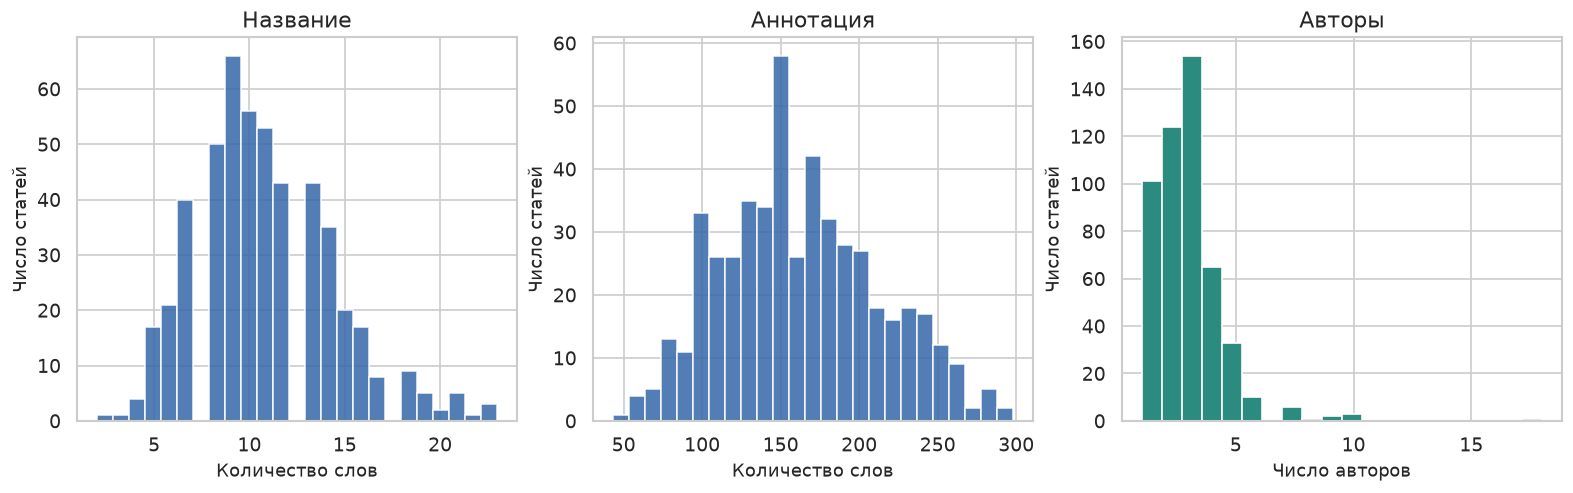

,"Название, слов","Аннотация, слов",Число авторов
count,500.00,500.00,500.00
mean,10.83,162.29,2.82
std,3.58,50.12,1.65
min,2.00,43.00,1.00
25%,8.00,126.00,2.00
50%,10.00,157.00,3.00
75%,13.00,196.00,3.00
max,23.00,298.00,18.00


In [10]:
for name, fig in corpus_figures(papers, texts):
    show_figure(fig)
lengths = pd.DataFrame({'Название, слов': [len(t['title']['zipf_tokens']) for t in texts],
                       'Аннотация, слов': [len(t['abstract']['zipf_tokens']) for t in texts],
                       'Число авторов': [len(p['authors']) for p in papers]})
show_table(lengths.describe().round(2))

### Проверка закона Ципфа

Сортирую слова по частоте. Самое частое слово получает первый ранг, следующее второй.
По закону Ципфа частота обычно уменьшается примерно обратно рангу.
Слова с высоким рангом встречаются значительно реже первых слов.

На графике обе оси имеют логарифмический масштаб. Если зависимость близка к закону
Ципфа, точки на части графика располагаются примерно вдоль прямой.
Для оценки беру ранги с 10 по 1000, где слово встретилось не меньше пяти раз.
Показатель s описывает скорость убывания частоты. Значение около единицы ожидаемо
для закона Ципфа. R2 показывает, насколько хорошо прямая описывает выбранный участок.
Высокое R2 не доказывает выполнение закона для всего распределения.
Название здесь учитывается один раз, как и аннотация.

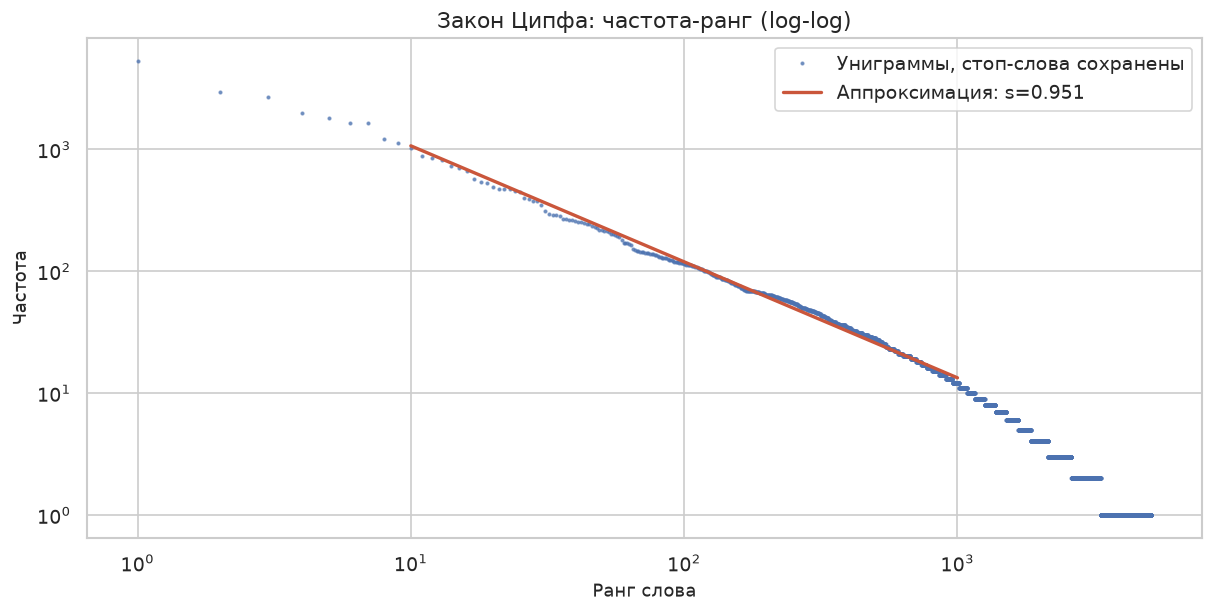

,rank,term,frequency
0,1,the,5311
1,2,of,2960
2,3,and,2655
3,4,a,1970
4,5,to,1795
5,6,be,1647
6,7,in,1646
7,8,we,1219
8,9,model,1124
9,10,for,1015


,status,s,intercept,r_squared,points,rank_min,rank_max,tokens,vocabulary
0,ok,0.951455,9.160641,0.993537,991,10,1000,86561,5120


Показатель s: 0.951
На выбранном участке частоты убывают примерно так, как ожидается по закону Ципфа.
Самые частые и редкие слова могут отклоняться от этой зависимости.


In [11]:
def zipf_analysis(texts):
    counts = Counter((t for row in texts for field in ('title', 'abstract') for t in row[field]['zipf_tokens']))
    ordered = sorted(counts.items(), key=lambda item: (-item[1], item[0]))
    frame = pd.DataFrame(ordered, columns=['term', 'frequency'])
    frame.insert(0, 'rank', np.arange(1, len(frame) + 1))
    fit = frame[(frame['rank'] >= 10) & (frame['rank'] <= 1000) & (frame['frequency'] >= 5)]
    if len(fit) < 3:
        return (frame, {'status': 'insufficient_points'})
    x, y = (np.log(fit['rank']), np.log(fit['frequency']))
    slope, intercept = np.polyfit(x, y, 1)
    residual = float(((y - (intercept + slope * x)) ** 2).sum())
    total = float(((y - y.mean()) ** 2).sum())
    return (frame, {'status': 'ok', 's': float(-slope), 'intercept': float(intercept), 'r_squared': 1 - residual / total if total else None, 'points': len(fit), 'rank_min': int(fit['rank'].min()), 'rank_max': int(fit['rank'].max()), 'tokens': sum(counts.values()), 'vocabulary': len(counts)})

zipf_frame, zipf_metrics = zipf_analysis(texts)
show_figure(zipf_figure(zipf_frame, zipf_metrics))
show_table(zipf_frame.head(20))
show_table(pd.DataFrame([zipf_metrics]))
if zipf_metrics['status'] == 'ok':
    print('Показатель s:', round(zipf_metrics['s'], 3))
    print('На выбранном участке частоты убывают примерно так, как ожидается по закону Ципфа.')
    print('Самые частые и редкие слова могут отклоняться от этой зависимости.')

## 6. Выделение ключевых слов

Для каждого кандидата считаю TF-IDF. Эта оценка повышается, когда термин часто
встречается в конкретной статье, но не встречается одинаково часто во всём корпусе.
Повторы учитываются с помощью логарифма, чтобы одно повторяемое слово не вытеснило остальные.
Нормировка уменьшает зависимость от длины текста.

У названия вес в два раза выше, чем у аннотации: обычно название коротко выражает тему.
Кандидат должен встречаться хотя бы в двух статьях и не более чем в 80 процентах корпуса.
Составные фразы получают небольшой бонус, чтобы не потерять конкретные понятия.
Из списка выбираю до 12 тегов. Если уже выбрана длинная фраза, её короткую часть отдельно
не добавляю. Это помогает не занять все места вариантами одного понятия.
Число тегов может быть меньше 12, если подходящих кандидатов мало.


 2001.01518 Disentangling shock diffusion on complex networks: Identification through graph planarity


,term_id,score,rank_score,ngram_size
0,shock,0.272132,0.272132,1
1,complex network,0.219522,0.263426,2
2,node,0.239743,0.239743,1
3,collapse,0.230353,0.230353,1
4,identification,0.224882,0.224882,1
5,propagation,0.211120,0.211120,1
6,loop,0.198451,0.198451,1
7,country,0.193423,0.193423,1
8,graph,0.175143,0.175143,1
9,collective dynamic,0.136050,0.163261,2


,field,start,end,text
0,title,14,19,shock
1,abstract,356,361,shock
2,abstract,844,849,shock
3,abstract,1067,1073,shocks



 2001.01612 A Note on Portfolio Optimization with Quadratic Transaction Costs


,term_id,score,rank_score,ngram_size
0,transaction cost,0.454843,0.545812,2
1,quadratic,0.374328,0.374328,1
2,numerical algorithm,0.249333,0.299199,2
3,portfolio optimization,0.215444,0.258533,2
4,budget,0.204560,0.204560,1
5,optimization problem,0.159787,0.191744,2
6,specification,0.181111,0.181111,1
7,constraint,0.140822,0.140822,1
8,variance,0.123360,0.123360,1
9,return,0.086766,0.086766,1


,field,start,end,text
0,title,48,65,Transaction Costs
1,abstract,72,89,transaction costs
2,abstract,126,143,transaction costs
3,abstract,208,225,transaction costs



 2001.02966 Clustering Approaches for Global Minimum Variance Portfolio


,term_id,score,rank_score,ngram_size
0,global minimum variance,0.291235,0.407729,3
1,covariance matrix,0.289877,0.347852,2
2,minimum variance portfolio,0.244545,0.342362,3
3,estimation error,0.244545,0.293453,2
4,cluster,0.244545,0.244545,1
5,population,0.202425,0.202425,1
6,high dimensionality,0.138775,0.166530,2
7,observed data,0.138775,0.166530,2
8,sample,0.156208,0.156208,1
9,portfolio weight,0.116527,0.139832,2


,field,start,end,text
0,title,26,49,Global Minimum Variance
1,abstract,50,73,global minimum variance


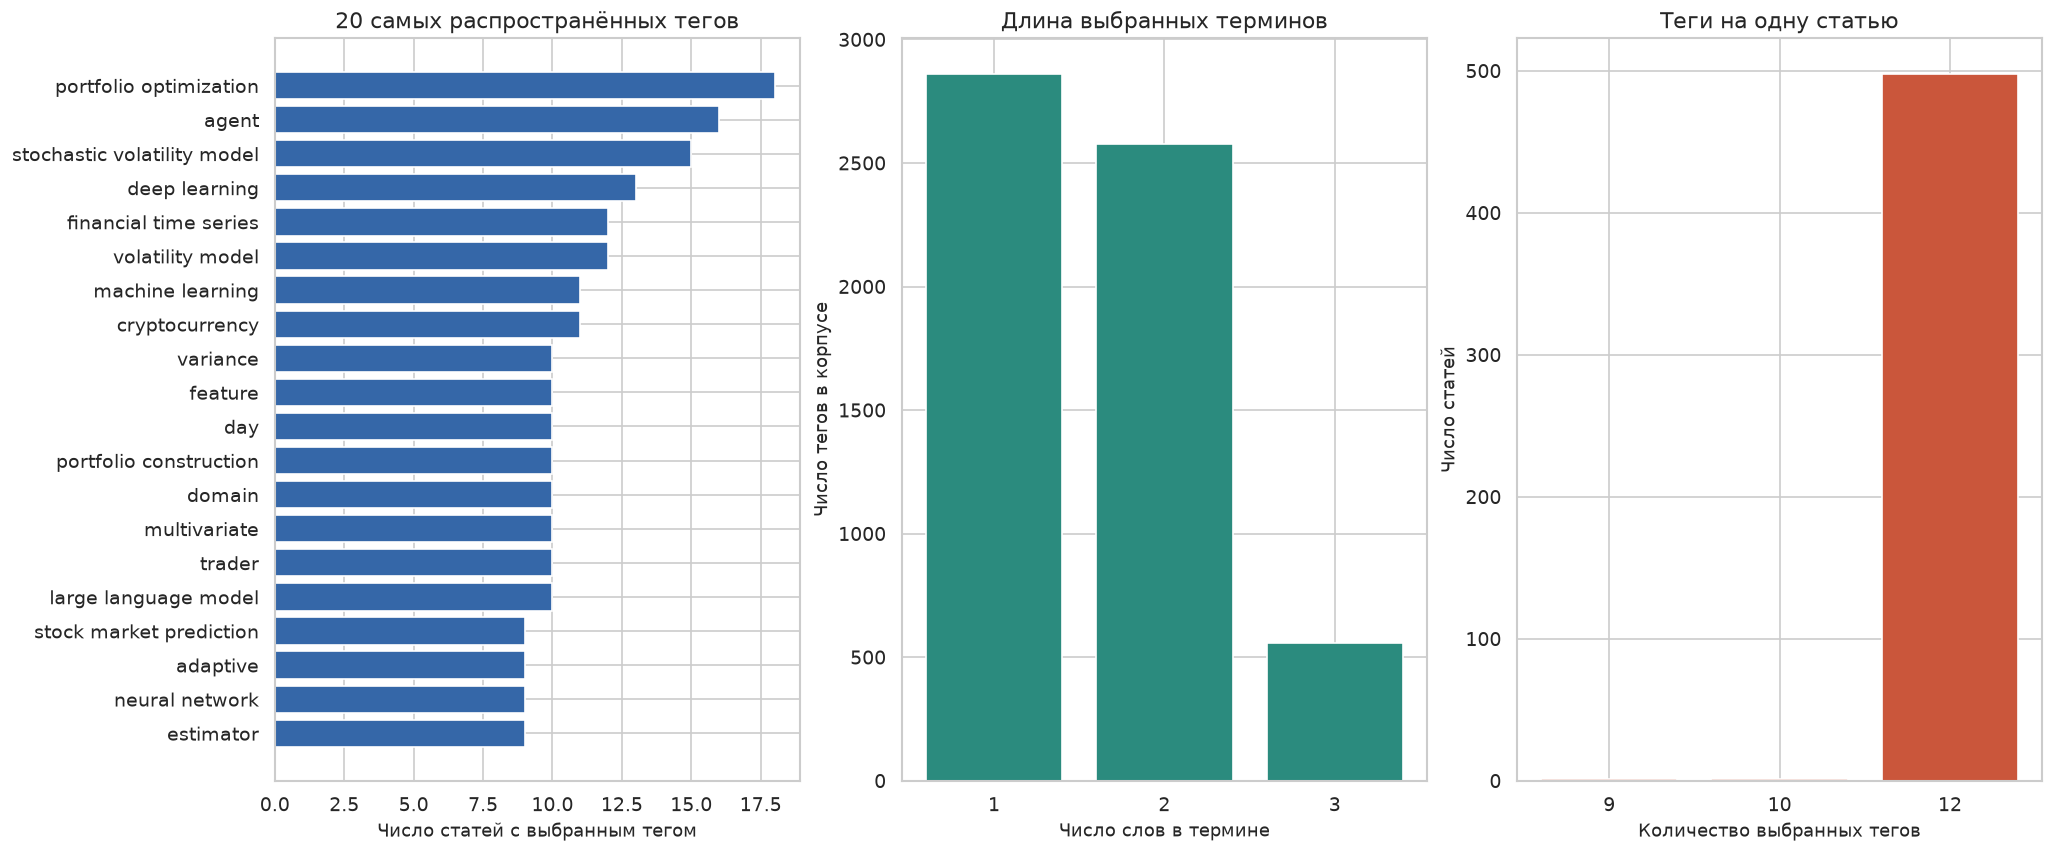

Статей с тегами: 100.0 процентов
Всего назначений тегов: 5995


,ID,Тематические теги,Общие или контекстные,Замечания
0,2001.01518,9,3,нет
1,2001.01612,8,2,нет
2,2001.03333,6,5,long short term
3,2001.06275,7,5,нет
4,2101.02287,8,3,long short term
5,2101.03086,10,2,нет
6,2101.03205,8,4,нет
7,2101.07107,8,4,нет
8,2201.02828,7,4,time risk
9,2202.03158,8,4,нет


In [12]:
def subphrase(a, b):
    x, y = (a.split(), b.split())
    return any((y[i:i + len(x)] == x for i in range(len(y) - len(x) + 1)))

def score_candidates(texts, settings):
    df = Counter()
    for row in texts:
        df.update(set(row['title']['counts']) | set(row['abstract']['counts']))
    terms = sorted((t for t, count in df.items() if settings['min_df'] <= count <= settings['max_df'] * len(texts)))
    if not terms:
        raise ValueError('Empty phrase vocabulary; review df filters')
    index = {t: i for i, t in enumerate(terms)}
    rr, cc, vv = ([], [], [])
    for i, row in enumerate(texts):
        counts = Counter()
        for field in ('title', 'abstract'):
            for term, count in row[field]['counts'].items():
                counts[term] += settings[field + '_weight'] * count
        for term, count in sorted(counts.items()):
            if term in index:
                rr.append(i)
                cc.append(index[term])
                vv.append(count)
    counts = csr_matrix((vv, (rr, cc)), shape=(len(texts), len(terms)), dtype=np.float64)
    scores = TfidfTransformer(sublinear_tf=True, smooth_idf=True, norm='l2').fit_transform(counts)
    return (terms, scores, df)

def select_keywords(texts, terms, scores, top_k=12, phrase_bonus=0.2):
    if not isinstance(top_k, int) or top_k < 1:
        raise ValueError('top_k must be a positive integer')
    rows = []
    for i, text in enumerate(texts):
        vector = scores.getrow(i)
        rank_score = lambda j, value: value * (1 + phrase_bonus * (len(terms[j].split()) - 1))
        ranked = sorted(zip(vector.indices, vector.data), key=lambda pair: (-rank_score(*pair), terms[pair[0]]))
        chosen = []
        for j, score in ranked:
            term = terms[j]
            if any((subphrase(term, c['term_id']) or subphrase(c['term_id'], term) for c in chosen)):
                continue
            evidence = sum((text[field]['evidence'].get(term, []) for field in ('title', 'abstract')), [])
            chosen.append({'term_id': term, 'display_term': evidence[0]['text'] if evidence else term, 'score': float(score), 'rank_score': float(rank_score(j, score)), 'ngram_size': len(term.split()), 'evidence': evidence})
            if len(chosen) == top_k:
                break
        rows.append({'paper_id': text['paper_id'], 'keywords': chosen})
    return rows

terms, scores, candidate_df = score_candidates(texts, cfg['keywords'])
keywords = select_keywords(texts, terms, scores, cfg['keywords']['top_k'], cfg['keywords']['phrase_bonus'])
tags_by_id = {row['paper_id']: row['keywords'] for row in keywords}
for paper in papers[:3]:
    print('\n', paper['paper_id'], plain(paper['title']))
    show_table(pd.DataFrame(tags_by_id[paper['paper_id']])[['term_id','score','rank_score','ngram_size']])
    show_table(pd.DataFrame(tags_by_id[paper['paper_id']][0]['evidence']))
show_figure(keyword_figures(keywords))
tag_coverage = sum(bool(row['keywords']) for row in keywords) / len(papers)
print('Статей с тегами:', round(tag_coverage * 100, 1), 'процентов')
print('Всего назначений тегов:', sum(len(row['keywords']) for row in keywords))
if same_corpus:
    audit = saved['keyword_audit']
    show_table(pd.DataFrame([{'ID': r['paper_id'], 'Тематические теги': len(r['topical_terms']),
                             'Общие или контекстные': len(r['general_or_context_terms']),
                             'Замечания': ', '.join(r['fragment_or_normalization_issues']) or 'нет'} for r in audit]))

Для 30 статей есть дополнительный просмотр тегов.
В таблице видно, что не все теги одинаково полезны: остаются общие слова и части
длинных названий методов. Поэтому дальше интерпретирую группы по нескольким словам
и примерам статей, а не по одному случайному тегу.

## 7. Построение графов

Сначала создаю таблицу принадлежности: строки соответствуют статьям, столбцы тегам.
Единица означает, что тег выбран для статьи. Каждый тег учитывается в статье один раз.
На основе этой общей таблицы строю оба графа в NetworkX.

В графе ключевых слов узел является тегом. Два тега связаны, если они выбраны
для одной статьи. Вес показывает число статей, где они встречаются вместе.

В графе публикаций узел является статьёй. Ребро появляется при хотя бы одном общем
теге. Вес равен числу общих тегов. Например, три общих тега дают вес три.
Статьи без соседей остаются в графе. Связи направлений не имеют, петель нет.
Это тематическое сходство, а не граф цитирования.

In [13]:
def build_graphs(papers, keywords):
    paper_ids = [p['paper_id'] for p in papers]
    if len(set(paper_ids)) != len(paper_ids):
        raise ValueError('Duplicate canonical paper IDs')
    tags = {r['paper_id']: {t['term_id'] for t in r['keywords']} for r in keywords}
    if set(tags) != set(paper_ids) or len(keywords) != len(papers):
        raise ValueError('Keyword records must cover exactly the corpus')
    terms = sorted(set().union(*tags.values()))
    index = {t: i for i, t in enumerate(terms)}
    rr, cc = ([], [])
    for i, pid in enumerate(paper_ids):
        for term in sorted(tags[pid]):
            rr.append(i)
            cc.append(index[term])
    incidence = csr_matrix((np.ones(len(rr), dtype=np.int32), (rr, cc)), shape=(len(papers), len(terms)))
    term_graph, paper_graph = (nx.Graph(), nx.Graph())
    freq = np.asarray(incidence.sum(axis=0)).ravel()
    term_graph.add_nodes_from(((term, {'tag_df': int(freq[i])}) for i, term in enumerate(terms)))
    paper_graph.add_nodes_from(((p['paper_id'], {'title': p['title'], 'published': p['published'], 'tag_count': len(tags[p['paper_id']])}) for p in papers))
    for graph, matrix, names in [(term_graph, incidence.T @ incidence, terms), (paper_graph, incidence @ incidence.T, paper_ids)]:
        upper = triu(matrix, k=1).tocoo()
        for i, j, weight in sorted(zip(upper.row, upper.col, upper.data)):
            graph.add_edge(names[i], names[j], weight=int(weight), distance=1.0 / int(weight))
    for a, b, edge in paper_graph.edges(data=True):
        shared = sorted(tags[a] & tags[b])
        edge.update(shared_terms=shared, jaccard=len(shared) / len(tags[a] | tags[b]))
    return (term_graph, paper_graph, incidence, paper_ids, terms)

def graph_stats(graph):
    components = sorted(nx.connected_components(graph), key=lambda c: (-len(c), min(c)))
    n = len(graph)
    return {'nodes': n, 'edges': graph.number_of_edges(), 'density': nx.density(graph), 'isolates': len(list(nx.isolates(graph))), 'components': len(components), 'largest_component': len(components[0]) if components else 0, 'largest_component_fraction': len(components[0]) / n if n else 0}

tg, pg, incidence, paper_ids, selected_terms = build_graphs(papers, keywords)
show_table(pd.DataFrame([{'Граф': 'Ключевые слова', **graph_stats(tg)},
                         {'Граф': 'Публикации', **graph_stats(pg)}]))

,Граф,nodes,edges,density,isolates,components,largest_component,largest_component_fraction
0,Ключевые слова,2662,32408,0.009150,0,1,2662,1.0
1,Публикации,500,6609,0.052978,0,1,500,1.0


## 8. Кластеры ключевых слов

Использую Louvain. Алгоритм объединяет узлы в сообщества, где связи внутри группы
сильнее, чем можно ожидать при случайном соединении с учётом связности узлов.
Для оценки такого разбиения использую взвешенную модулярность.
Это характеристика структуры графа, а не процент правильно определённых тем.

Основной вариант использует seed 42 и resolution 1. Seed нужен для повторяемости.
Дополнительно сравниваю несколько seed, другую детализацию и жадный алгоритм.
ARI сравнивает принадлежность узлов группам с основным разбиением.
У разных resolution меняется целевая функция, поэтому их модулярность
нельзя напрямую сравнивать как качество одной и той же задачи.

,method,seed,resolution,communities,modularity,ari_to_seed42
0,louvain,42.0,1.0,22,0.4112,1.0000
1,louvain,43.0,1.0,20,0.4136,0.2105
2,louvain,44.0,1.0,20,0.4132,0.2091
3,louvain,42.0,0.5,2,0.5058,0.0555
4,louvain,42.0,1.5,38,0.3891,0.4478
5,greedy,NaN,1.0,11,0.3660,0.0967


Найдено сообществ: 22
Модулярность: 0.4112


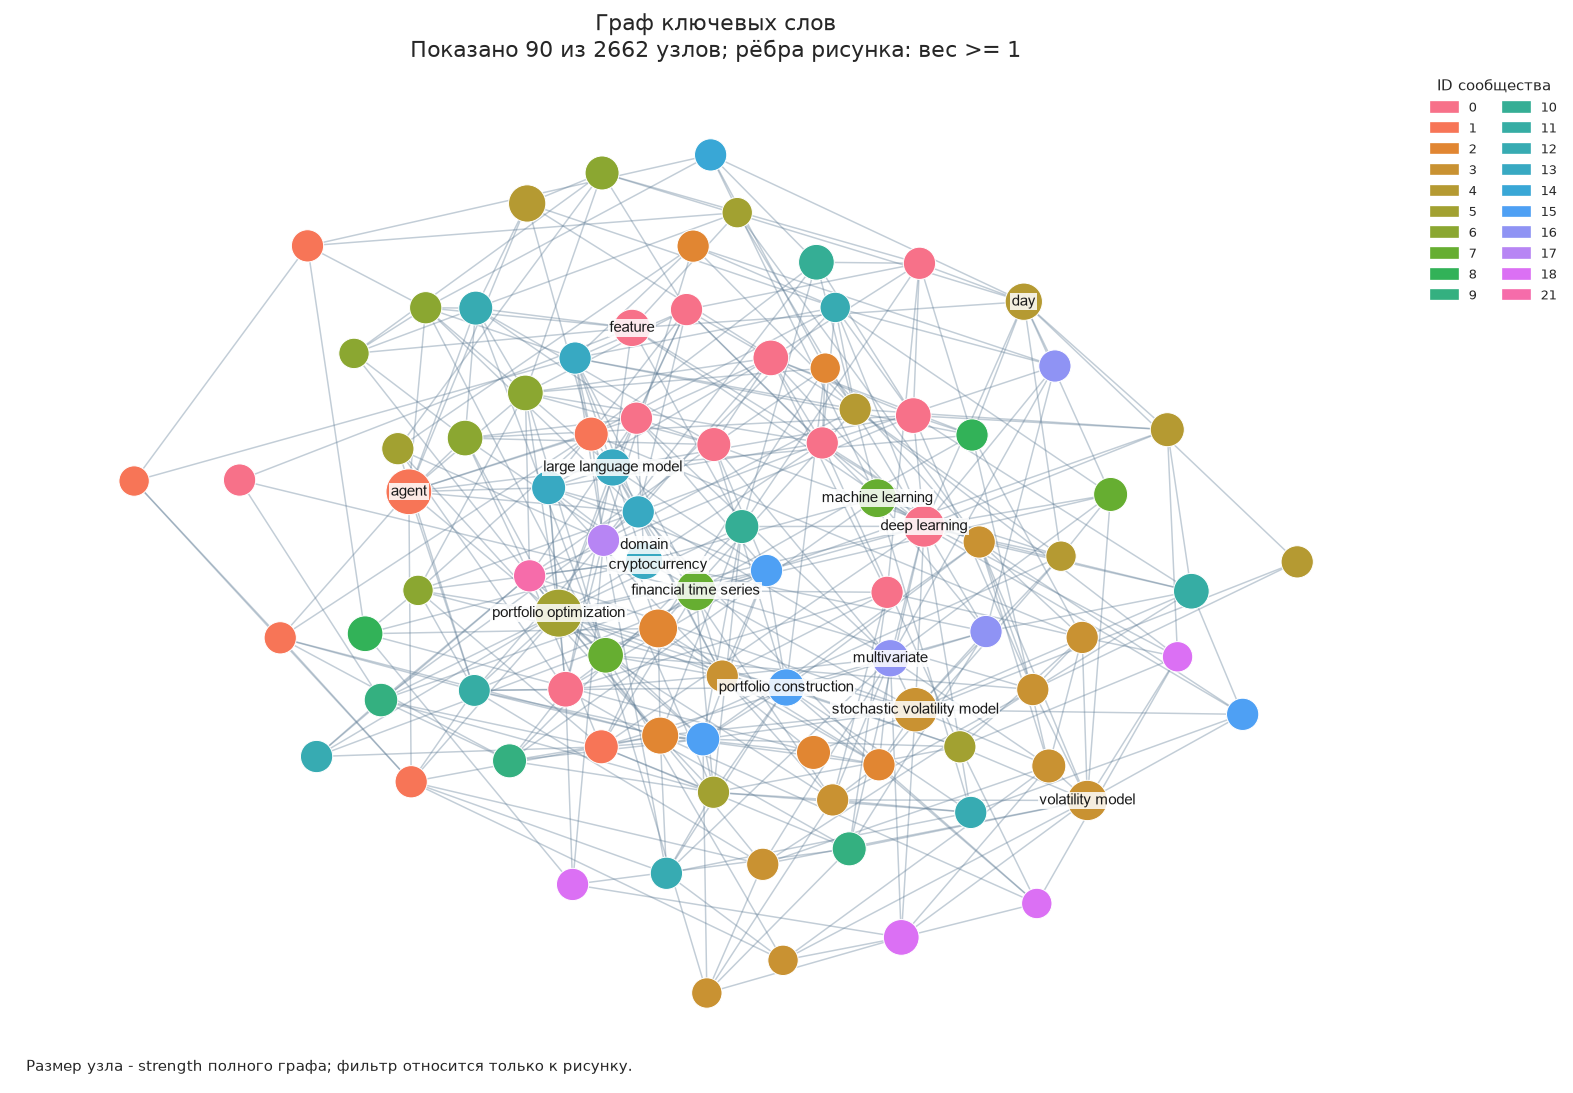

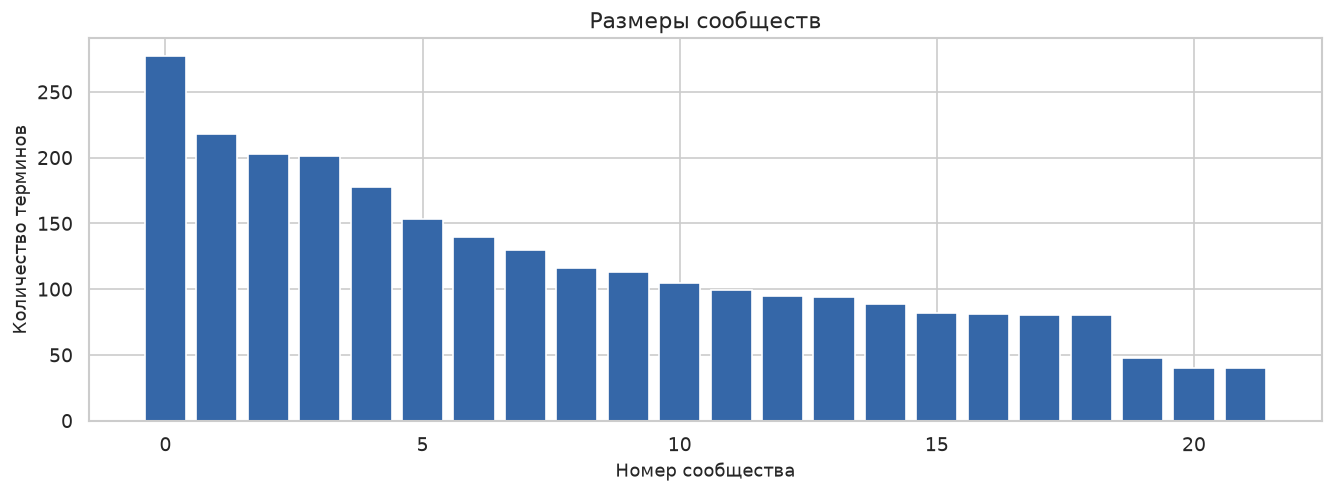

In [14]:
def partition(graph, seed=42, resolution=1.0, method='louvain'):
    if not graph.number_of_edges():
        return ([{node} for node in sorted(graph)], None)
    if method == 'louvain':
        communities = nx.community.louvain_communities(graph, weight='weight', seed=seed, resolution=resolution)
    elif method == 'greedy':
        communities = list(nx.community.greedy_modularity_communities(graph, weight='weight', resolution=resolution))
    else:
        raise ValueError('Unknown community method')
    communities = sorted(communities, key=lambda c: (-len(c), min(c)))
    modularity = nx.community.modularity(graph, communities, weight='weight', resolution=resolution)
    return (communities, float(modularity))

def community_experiments(graph, settings):
    rows, labels = ([], {})
    base, _ = partition(graph, seed=settings['seeds'][0], resolution=1)

    def assignments(groups):
        by_node = {n: i for i, nodes in enumerate(groups) for n in nodes}
        return [by_node[n] for n in sorted(graph)]
    reference = assignments(base)
    for seed in settings['seeds']:
        groups, q = partition(graph, seed=seed)
        rows.append({'method': 'louvain', 'seed': seed, 'resolution': 1.0, 'communities': len(groups), 'modularity': q, 'ari_to_seed42': float(adjusted_rand_score(reference, assignments(groups)))})
    for resolution in settings['resolutions']:
        if resolution != 1:
            groups, q = partition(graph, seed=settings['seeds'][0], resolution=resolution)
            rows.append({'method': 'louvain', 'seed': settings['seeds'][0], 'resolution': resolution, 'communities': len(groups), 'modularity': q, 'ari_to_seed42': float(adjusted_rand_score(reference, assignments(groups)))})
    groups, q = partition(graph, method='greedy')
    rows.append({'method': 'greedy', 'seed': None, 'resolution': 1.0, 'communities': len(groups), 'modularity': q, 'ari_to_seed42': float(adjusted_rand_score(reference, assignments(groups)))})
    return (base, rows)

groups, experiments = community_experiments(tg, cfg['analysis'])
modularity = nx.community.modularity(tg, groups, weight='weight', resolution=1)
show_table(pd.DataFrame(experiments).round(4))
print('Найдено сообществ:', len(groups))
print('Модулярность:', round(modularity, 4))
show_figure(graph_figure(tg, groups, cfg['visualization']['max_nodes'], cfg['visualization']['max_labels'], cfg['seed'], 'Граф ключевых слов'))
fig, ax = plt.subplots(figsize=(11,4), layout='constrained')
ax.bar(range(len(groups)), [len(group) for group in groups], color='#3567a8')
ax.set(xlabel='Номер сообщества', ylabel='Количество терминов', title='Размеры сообществ')
show_figure(fig)

### Объяснение полученных групп

На рисунке показаны только 90 наиболее связанных узлов, чтобы подписи можно было прочитать.
Размер узла зависит от суммы весов его рёбер в полном графе. Цвет обозначает сообщество.
Все расчёты сделаны на полном графе.

Названия групп выбираю после просмотра ведущих тегов и конкретных статей.
Сами названия не передаются алгоритму. В следующей таблице для каждой группы
показаны её слова и объяснение. Примеры относятся к статьям, у которых есть теги этой группы.
После обновления данных прежние названия применяются только при совпадении разбиения.

In [15]:
community_signature = digest(json.dumps([sorted(group) for group in groups], ensure_ascii=False).encode())
same_communities = same_corpus and community_signature == saved['community_signature']
notes = {row['community_id']: row for row in saved['community_notes']} if same_communities else {}
paper_lookup = {paper['paper_id']: paper for paper in papers}
tag_sets = {row['paper_id']: {tag['term_id'] for tag in row['keywords']} for row in keywords}
community_rows = []
for number, group in enumerate(groups):
    leaders = sorted(group, key=lambda term: (-tg.degree(term, weight='weight'), term))[:8]
    note = notes.get(number)
    community_rows.append({'Группа': number, 'Терминов': len(group),
                           'Название': note['label'] if note else ' / '.join(leaders[:3]),
                           'Ведущие теги': ', '.join(leaders)})
show_table(pd.DataFrame(community_rows))
for row in community_rows:
    number = row['Группа']
    note = notes.get(number)
    print('\nГруппа', number, '-', row['Название'])
    print('Теги:', row['Ведущие теги'])
    if note:
        print(plain(note['explanation']))
        example_ids = note['example_ids']
    else:
        leaders = row['Ведущие теги'].split(', ')
        example_ids = sorted(paper_lookup, key=lambda pid: (-len(tag_sets[pid] & set(leaders)), pid))[:2]
        print('Эти теги объединены, потому что часто выбираются вместе для одних статей.')
    for pid in example_ids:
        assert tag_sets[pid] & groups[number]
        print('Пример:', pid, plain(paper_lookup[pid]['title']))

print('\nЧасть групп смешанная: одна статья может одновременно описывать риск, прогноз и торговые решения.')
print('В основном корпусе видны нейросетевой прогноз, волатильность, торговые агенты, портфели и языковые модели.' if same_communities else 'Для нового корпуса названия групп требуют отдельного просмотра.')

,Группа,Терминов,Название,Ведущие теги
0,0,277,Нейросетевой прогноз акций и текстовые признаки,"deep learning, feature, neural network, sentiment, stock market prediction, portfolio management..."
1,1,218,"Агенты, оптимальное инвестирование и контроль","agent, behaviour, var, evaluation, optimal investment, optimal strategy, control, existence"
2,2,203,"Криптоактивы, ликвидность и волатильность","cryptocurrency, variance, liquidity, bitcoin, garch model, evolution, hurst exponent, hypothesis"
3,3,201,Стохастическая и rough-волатильность,"stochastic volatility model, volatility model, fractional brownian motion, deep learning model, ..."
4,4,178,Микроструктура и поток ордеров,"day, trader, volume, law, spread, bitcoin price, order flow, price impact"
5,5,153,Оптимизация портфеля и факторы риска,"portfolio optimization, measure, momentum, risk factor, deep neural network, firm, shock, high v..."
6,6,140,Reinforcement learning торговых решений,"deep reinforcement learning, multi, trading strategy, reinforcement learning, diversification, d..."
7,7,130,Статистическое обучение финансовых рядов,"financial time series, machine learning, adaptive, forecasting, tail, gaussian, point, asset pri..."
8,8,116,Робастные и гибридные портфельные алгоритмы,"portfolios, stock price, quantum, solution, exchange rate, portfolio optimization problem, hybri..."
9,9,113,"GARCH, зависимости и распределения","garch, uncertainty, distribution, portfolio selection, sector, stochastic volatility, copula, pr..."



Группа 0 - Нейросетевой прогноз акций и текстовые признаки
Теги: deep learning, feature, neural network, sentiment, stock market prediction, portfolio management, company, index
LSTM, neural network и sentiment связываются через статьи о stock prediction; присутствуют переходы к портфельным RL-задачам.
Пример: 2001.03333 A new approach for trading based on Long Short Term Memory technique
Пример: 2002.06975 Cross-sectional Stock Price Prediction using Deep Learning for Actual Investment Management

Группа 1 - Агенты, оптимальное инвестирование и контроль
Теги: agent, behaviour, var, evaluation, optimal investment, optimal strategy, control, existence
Agent, optimal strategy и control объединяет последовательное принятие решений; сюда попадают игры и стохастическое инвестирование.
Пример: 2002.08286 Price impact equilibrium with transaction costs and TWAP trading
Пример: 2401.07183 Optimal Investment with Herd Behaviour Using Rational Decision Decomposition

Группа 2 - Криптоактивы, ли

## 9. Центральности

Считаю четыре меры, потому что важность слова можно понимать по-разному.

- Degree centrality показывает, с какой долей остальных понятий связан термин.
- Betweenness показывает, насколько часто термин лежит на кратчайших путях между другими словами.
- Closeness показывает, насколько близко термин расположен к достижимым словам графа.
- Eigenvector учитывает, насколько важны сами соседи термина.

Вес ребра обозначает силу связи. Для поиска пути сильная связь должна быть короткой,
поэтому в качестве расстояния беру единицу, разделённую на вес.
Для betweenness и closeness использую это расстояние.
Для eigenvector и Louvain использую исходные веса.
Eigenvector считаю для самой большой связной части графа. Для остальных узлов оставляю пропуск.
Сумма весов рёбер, или strength, выводится отдельно и не подменяет degree centrality.
Из-за коротких расстояний closeness может быть больше единицы.


Первые десять терминов по degree


,term_id,degree,strength,tag_df
1792,portfolio optimization,0.066141,196,18
36,agent,0.060128,176,16
2299,stochastic volatility model,0.054867,165,15
511,deep learning,0.051860,143,13
890,financial time series,0.047351,132,12
2616,volatility model,0.045847,132,12
1370,machine learning,0.043968,121,11
460,cryptocurrency,0.042841,121,11
814,feature,0.040962,110,10
2469,trader,0.040586,110,10



Первые десять терминов по betweenness


,term_id,betweenness,strength,tag_df
1792,portfolio optimization,0.062097,196,18
36,agent,0.048409,176,16
2299,stochastic volatility model,0.034145,165,15
1276,large language model,0.020895,110,10
511,deep learning,0.018983,143,13
520,deep reinforcement learning,0.018930,99,9
2571,variance,0.018598,108,10
460,cryptocurrency,0.017582,121,11
890,financial time series,0.017559,132,12
2616,volatility model,0.016461,132,12



Первые десять терминов по closeness


,term_id,closeness,strength,tag_df
1792,portfolio optimization,0.521245,196,18
36,agent,0.498517,176,16
520,deep reinforcement learning,0.491178,99,9
2299,stochastic volatility model,0.489065,165,15
385,constraint,0.483203,86,8
1276,large language model,0.481114,110,10
2571,variance,0.479136,108,10
43,algorithm,0.476775,77,7
1588,neural network,0.473228,99,9
511,deep learning,0.470031,143,13



Первые десять терминов по eigenvector


,term_id,eigenvector,strength,tag_df
1792,portfolio optimization,0.163625,196,18
36,agent,0.125125,176,16
2299,stochastic volatility model,0.117077,165,15
1276,large language model,0.103371,110,10
511,deep learning,0.099300,143,13
1342,llms,0.090577,88,8
520,deep reinforcement learning,0.085592,99,9
2616,volatility model,0.082909,132,12
607,domain,0.082728,110,10
890,financial time series,0.081454,132,12


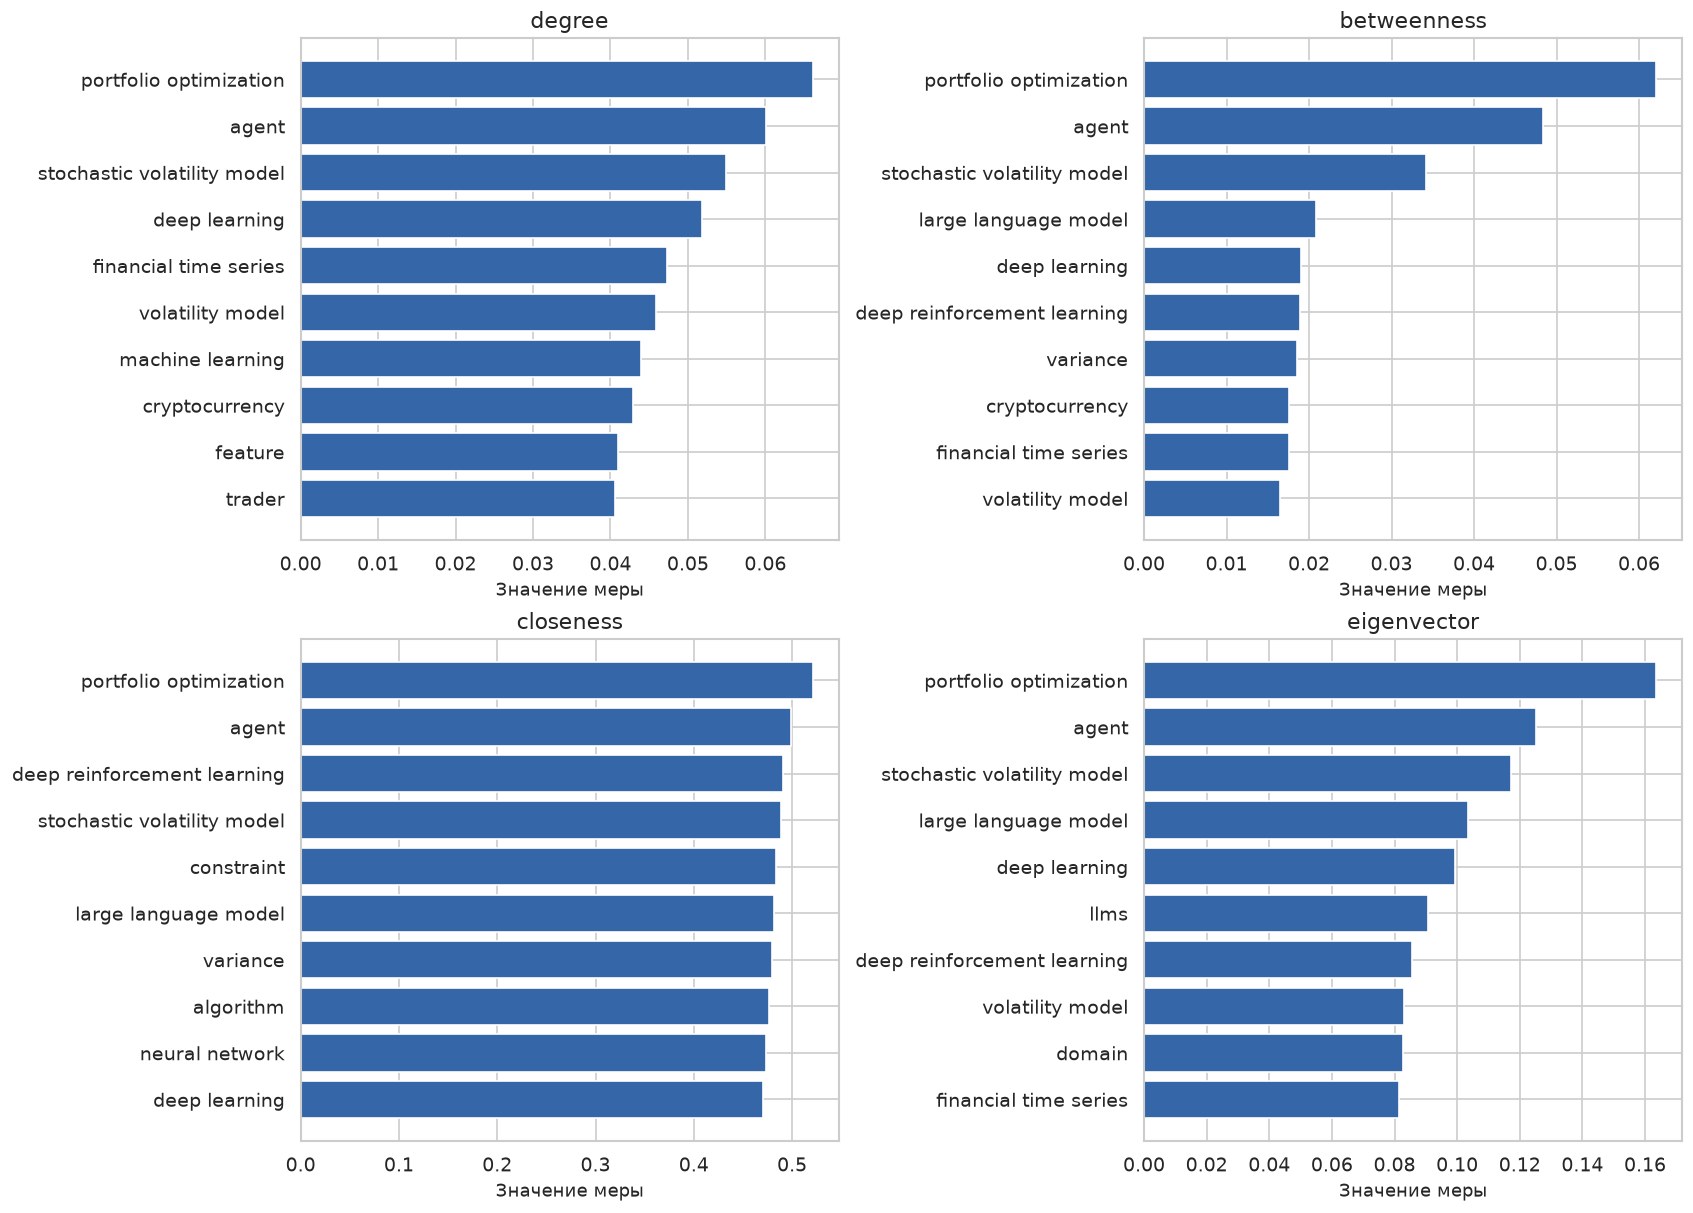

,degree,betweenness,closeness,eigenvector
degree,1.000,0.973,0.839,0.868
betweenness,0.973,1.000,0.812,0.824
closeness,0.839,0.812,1.000,0.974
eigenvector,0.868,0.824,0.974,1.000



Термин: portfolio optimization


,term_id,degree,betweenness,closeness,eigenvector
1792,portfolio optimization,0.066141,0.062097,0.521245,0.163625


Пример статьи: 2001.01612 A Note on Portfolio Optimization with Quadratic Transaction Costs
Пример статьи: 2001.09404 Semi-metric portfolio optimization: a new algorithm reducing simultaneous asset shocks

Термин: agent


,term_id,degree,betweenness,closeness,eigenvector
36,agent,0.060128,0.048409,0.498517,0.125125


Пример статьи: 2002.03379 Optimal liquidation for a risk averse investor in a one-sided limit order book driven by a Levy process
Пример статьи: 2002.08286 Price impact equilibrium with transaction costs and TWAP trading

Термин: stochastic volatility model


,term_id,degree,betweenness,closeness,eigenvector
2299,stochastic volatility model,0.054867,0.034145,0.489065,0.117077


Пример статьи: 2009.10972 The characteristic function of Gaussian stochastic volatility models: an analytic expression
Пример статьи: 2012.09082 The Averaging Principle for Non-autonomous Slow-fast Stochastic Differential Equations and an Application to a Local Stochastic Volatility Model

Термин: large language model


,term_id,degree,betweenness,closeness,eigenvector
1276,large language model,0.034949,0.020895,0.481114,0.103371


Пример статьи: 2401.11011 BioFinBERT: Finetuning Large Language Models (LLMs) to Analyze Sentiment of Press Releases and Financial Text Around Inflection Points of Biotech Stocks
Пример статьи: 2402.06698 FNSPID: A Comprehensive Financial News Dataset in Time Series


In [16]:
def centralities(graph, settings):
    degree = nx.degree_centrality(graph)
    betweenness = nx.betweenness_centrality(graph, weight='distance', normalized=True)
    closeness = nx.closeness_centrality(graph, distance='distance', wf_improved=True)
    components = sorted(nx.connected_components(graph), key=lambda c: (-len(c), min(c)))
    component_ids = {node: i for i, nodes in enumerate(components) for node in nodes}
    eigen, eigen_status = ({}, 'no_nontrivial_component')
    if components and len(components[0]) >= 2:
        eigen = nx.eigenvector_centrality(graph.subgraph(components[0]), weight='weight', max_iter=settings['eigenvector_max_iter'], tol=settings['eigenvector_tol'])
        eigen_status = 'converged'
    rows = [{'term_id': node, 'degree': degree[node], 'betweenness': betweenness[node], 'closeness': closeness[node], 'eigenvector': eigen.get(node), 'strength': int(graph.degree(node, weight='weight')), 'component_id': component_ids[node], 'tag_df': graph.nodes[node]['tag_df']} for node in sorted(graph)]
    return (rows, {'eigenvector_status': eigen_status, 'eigenvector_nodes': len(eigen), 'betweenness': 'exact'})

centrality_rows, centrality_status = centralities(tg, cfg['analysis'])
central = pd.DataFrame(centrality_rows)
for measure in ['degree','betweenness','closeness','eigenvector']:
    print('\nПервые десять терминов по', measure)
    show_table(central.dropna(subset=[measure]).sort_values([measure,'term_id'], ascending=[False,True]).head(10)[['term_id',measure,'strength','tag_df']])
show_figure(centrality_figure(centrality_rows))
show_table(central[['degree','betweenness','closeness','eigenvector']].corr(method='spearman').round(3))
for term in ['portfolio optimization','agent','stochastic volatility model','large language model']:
    if term in tg:
        print('\nТермин:', term)
        show_table(central[central['term_id'] == term][['term_id','degree','betweenness','closeness','eigenvector']])
        for pid in sorted(pid for pid in paper_lookup if term in tag_sets[pid])[:2]:
            print('Пример статьи:', pid, plain(paper_lookup[pid]['title']))

В основном корпусе portfolio optimization занимает первое место по всем четырём мерам.
Это понятие встречается рядом с разными способами решения инвестиционной задачи.
Agent объединяет торговые решения, обучение с подкреплением и управление.
Stochastic volatility model связывает моделирование риска, прогноз и оценку инструментов.
Large language model заметен как связующее понятие между текстовыми признаками
и финансовыми задачами. Такие выводы относятся к структуре выбранного корпуса.
Высокая центральность не означает, что метод лучше других или даёт большую прибыль.

## 10. Граф публикаций и поиск похожих статей

На рисунке показываю 70 узлов, но поиск работает по всем статьям.
Простой вариант neighbors выбирает прямых соседей по числу общих тегов.
При равенстве сравнивает долю общих тегов среди всех тегов двух статей,
а затем ID. Исходная статья в ответ не попадает.

Второй вариант использует Personalized PageRank, сокращённо PPR.
Можно представить, что мы перемещаемся по графу от исходной статьи.
На каждом шаге с вероятностью 0.85 продолжаем переход, а с вероятностью 0.15
возвращаемся к исходной статье. Сильные рёбра выбираются чаще.
Поэтому PPR может находить статьи через промежуточные публикации.
Его оценка не является числом общих тегов или вероятностью смысловой релевантности.

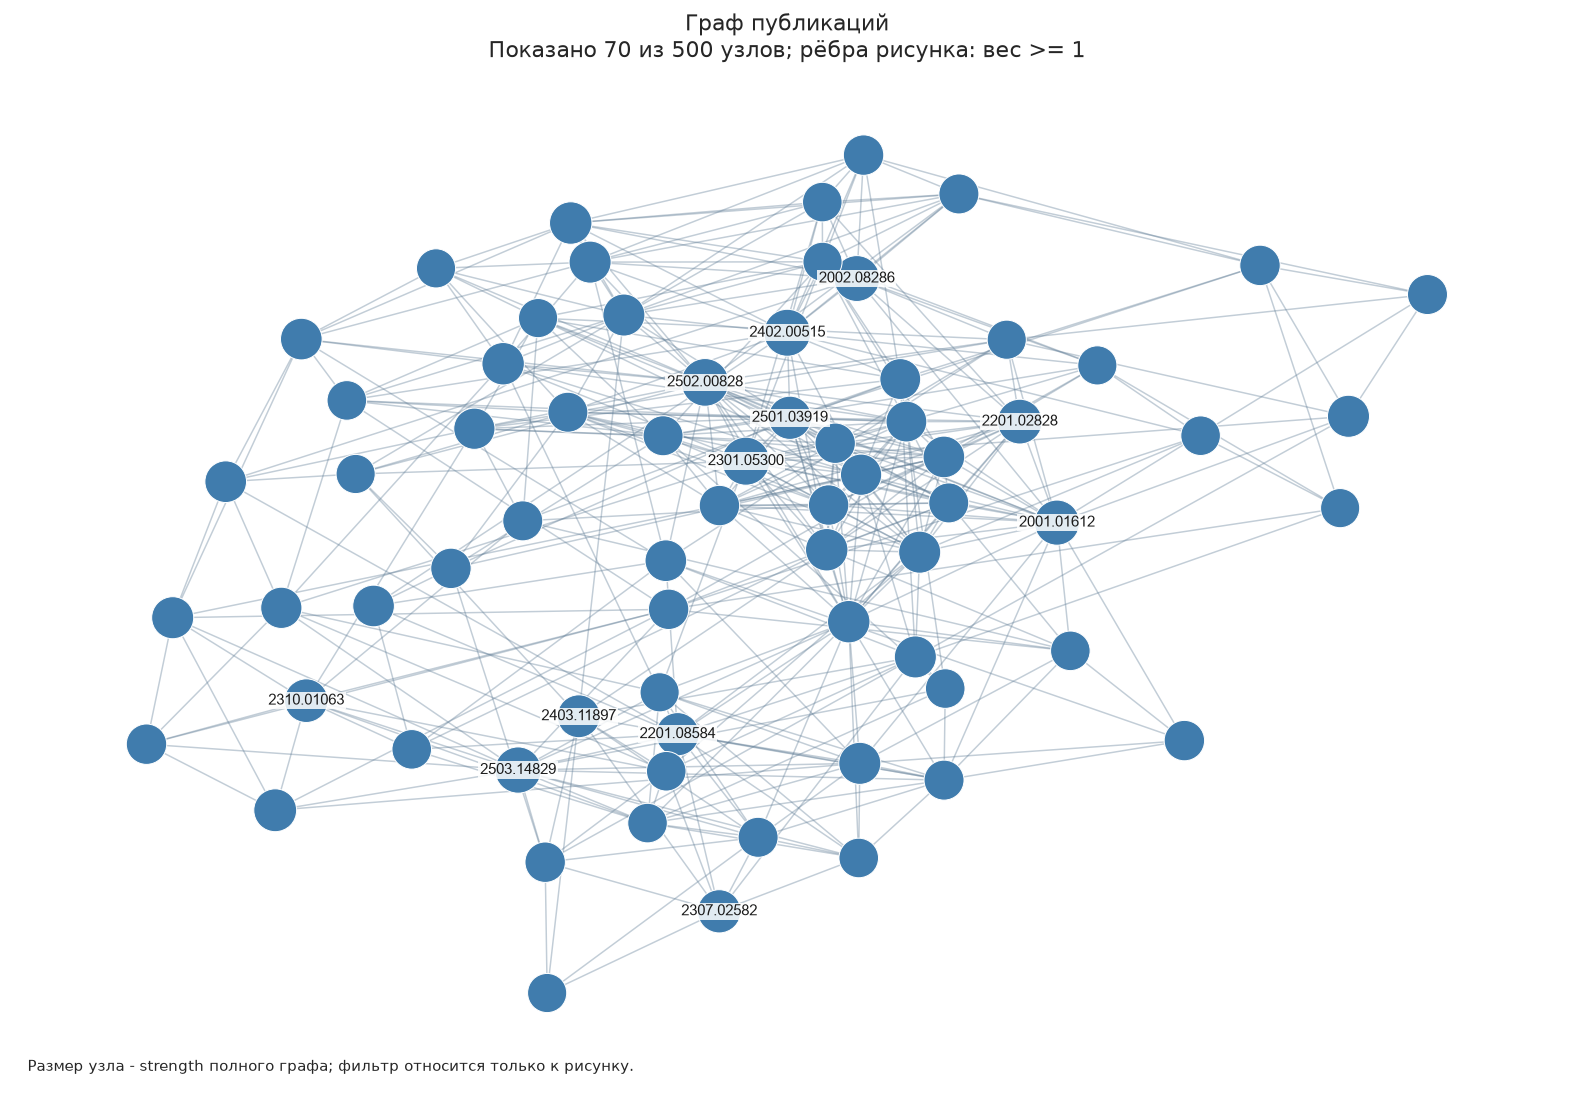

In [17]:
show_figure(graph_figure(pg, max_nodes=70, max_labels=12, seed=cfg['seed'], title='Граф публикаций'))

Исходная статья: 2001.01612 A Note on Portfolio Optimization with Quadratic Transaction Costs
Метод: neighbors
Статус: найдены результаты


,Место,ID,Название,Год,Оценка,Общие теги,Связь,Вес прямого ребра
0,1,2103.04432,Portfolio Optimization Constrained by Performance Attribution,2021,2.0,"constraint, portfolio optimization",прямая,2
1,2,2103.05455,Portfolio Construction as Linearly Constrained Separable Optimization,2021,2.0,"constraint, optimization problem",прямая,2
2,3,2201.02828,Discrete-time risk sensitive portfolio optimization with proportional transaction costs,2022,2.0,"portfolio optimization, transaction cost",прямая,2
3,4,2306.11158,Mind the Cap! -- Constrained Portfolio Optimisation in Heston's Stochastic Volatility Model,2023,2.0,"constraint, portfolio optimization",прямая,2
4,5,2605.02666,Pareto frontier of portfolio investment under volatility uncertainty and short-sale constraints ...,2026,2.0,"constraint, variance",прямая,2


Метод: ppr
Статус: найдены результаты


,Место,ID,Название,Год,Оценка,Общие теги,Связь,Вес прямого ребра
0,1,2201.02828,Discrete-time risk sensitive portfolio optimization with proportional transaction costs,2022,0.009183,"portfolio optimization, transaction cost",прямая,2
1,2,2306.11158,Mind the Cap! -- Constrained Portfolio Optimisation in Heston's Stochastic Volatility Model,2023,0.009059,"constraint, portfolio optimization",прямая,2
2,3,2103.04432,Portfolio Optimization Constrained by Performance Attribution,2021,0.008912,"constraint, portfolio optimization",прямая,2
3,4,2605.02666,Pareto frontier of portfolio investment under volatility uncertainty and short-sale constraints ...,2026,0.008238,"constraint, variance",прямая,2
4,5,2103.05455,Portfolio Construction as Linearly Constrained Separable Optimization,2021,0.007937,"constraint, optimization problem",прямая,2


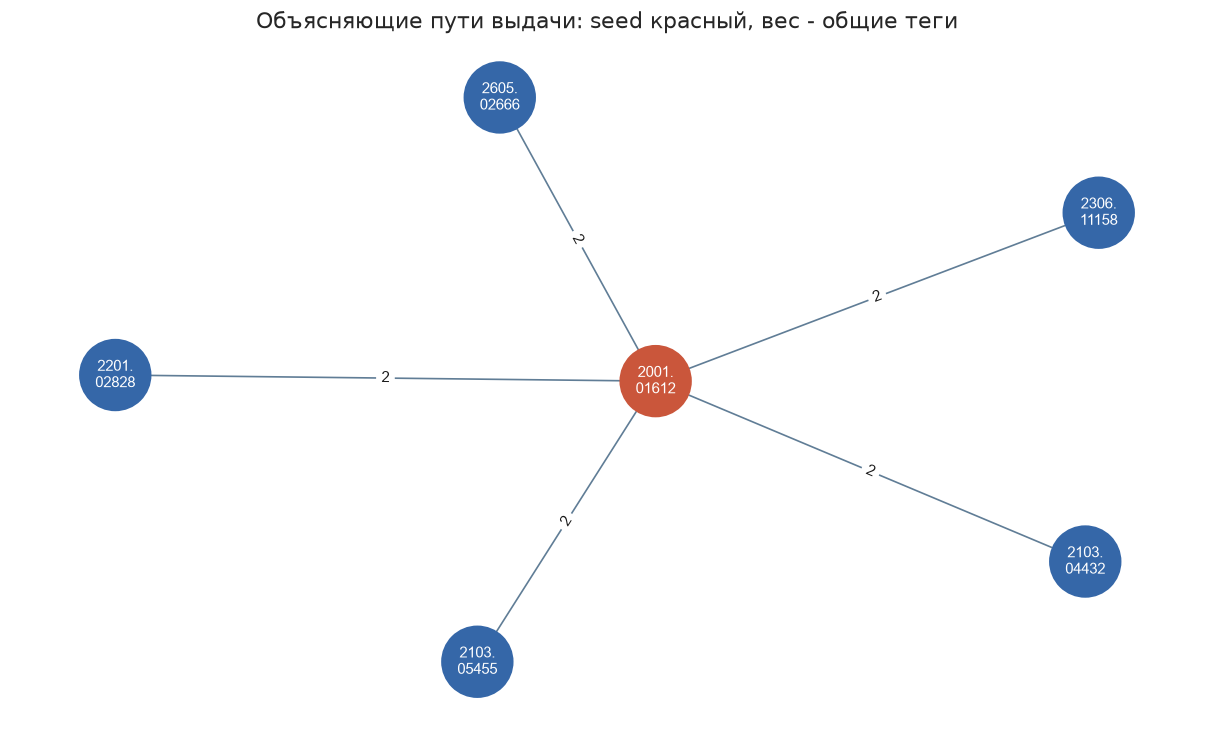

,source,target,shared_terms,weight
0,2001.01612,2201.02828,"[portfolio optimization, transaction cost]",2


In [18]:
class SearchEngine:

    def __init__(self, graph, papers, keywords, processor=None, settings=None):
        self.graph = graph
        self.papers = {p['paper_id']: p for p in papers}
        self.tags = {p['paper_id']: {t['term_id'] for t in p['keywords']} for p in keywords}
        self.index = defaultdict(set)
        for pid, tags in self.tags.items():
            for term in tags:
                self.index[term].add(pid)
        self.titles = defaultdict(list)
        for pid, paper in self.papers.items():
            self.titles[paper['title'].casefold()].append(pid)
        self.processor = processor
        self.settings = settings or {'alpha': 0.85, 'max_iter': 1000, 'tol': 1e-10}

    @staticmethod
    def validate_top_k(top_k):
        if isinstance(top_k, bool) or not isinstance(top_k, int) or top_k < 1:
            raise ValueError('top_k must be a positive integer')

    def resolve(self, value):
        pid = canonical_id(value)
        if pid in self.papers:
            return (pid, 'ok')
        matches = self.titles.get(str(value).strip().casefold(), [])
        if len(matches) == 1:
            return (matches[0], 'ok')
        return (None, 'ambiguous_title' if matches else 'unknown_paper')

    def _response(self, query, method, status='ok', terms=None, seeds=None, results=None, **diagnostics):
        return {'status': status, 'query': query, 'method': method, 'recognized_terms': terms or [], 'seed_ids': sorted(seeds or []), 'results': results or [], 'diagnostics': diagnostics}

    def _rows(self, ranked, seeds, query_terms, selected_paper=None):
        _, paths = nx.multi_source_dijkstra(self.graph, sorted(seeds), weight='distance')
        rows = []
        for rank, (pid, score) in enumerate(ranked, 1):
            path = paths[pid]
            shared = sorted(self.tags[pid] & (self.tags[selected_paper] if selected_paper else set(query_terms)))
            edges = [{'source': a, 'target': b, 'shared_terms': self.graph[a][b]['shared_terms'], 'weight': self.graph[a][b]['weight']} for a, b in zip(path, path[1:])]
            rows.append({'rank': rank, 'paper_id': pid, 'title': self.papers[pid]['title'], 'year': int(self.papers[pid]['published'][:4]), 'url': self.papers[pid]['abstract_url'], 'score': float(score), 'shared_terms': shared, 'relation_type': 'seed' if pid in seeds else 'direct' if any((self.graph.has_edge(seed, pid) for seed in seeds)) else 'indirect', 'path': path, 'path_edges': edges, 'direct_weight': self.graph[selected_paper][pid]['weight'] if selected_paper and self.graph.has_edge(selected_paper, pid) else None})
        return rows

    def _ppr(self, seeds, exclude, top_k):
        reachable = set().union(*(nx.node_connected_component(self.graph, seed) for seed in seeds))
        graph = self.graph.subgraph(sorted(reachable)).copy()
        total = sum(seeds.values())
        personalization = {n: seeds.get(n, 0) / total for n in graph}
        scores = nx.pagerank(graph, alpha=self.settings['alpha'], personalization=personalization, dangling=personalization, weight='weight', max_iter=self.settings['max_iter'], tol=self.settings['tol'])
        ranking = sorted(((n, s) for n, s in scores.items() if n not in exclude and s > 0), key=lambda pair: (-pair[1], pair[0]))
        return (ranking[:top_k], scores)

    def related(self, value, top_k=5, method='neighbors'):
        self.validate_top_k(top_k)
        if method not in {'neighbors', 'ppr'}:
            raise ValueError('Use neighbors or ppr')
        pid, status = self.resolve(value)
        if status != 'ok':
            return self._response(value, method, status)
        if self.graph.degree(pid) == 0:
            return self._response(value, method, 'isolated_paper', seeds={pid})
        if method == 'neighbors':
            neighbors = sorted(self.graph[pid], key=lambda n: (-self.graph[pid][n]['weight'], -self.graph[pid][n]['jaccard'], n))
            ranked = [(n, self.graph[pid][n]['weight']) for n in neighbors[:top_k]]
            diagnostics = {}
        else:
            try:
                ranked, scores = self._ppr({pid: 1}, {pid}, top_k)
            except nx.PowerIterationFailedConvergence:
                return self._response(value, method, 'convergence_failed', seeds={pid})
            diagnostics = {'ppr_mass': float(sum(scores.values()))}
        return self._response(value, method, results=self._rows(ranked, {pid: 1}, [], pid), seeds={pid}, **diagnostics)

    def by_text(self, query, top_k=5, method='ppr'):
        self.validate_top_k(top_k)
        if method not in {'ppr', 'overlap'}:
            raise ValueError('Use ppr or overlap')
        if not str(query).strip():
            return self._response(query, method, 'empty_query')
        if self.processor is None:
            raise ValueError('Text retrieval requires the corpus TextProcessor')
        terms = self.processor.query_terms(query, self.index)
        if not terms:
            return self._response(query, method, 'no_matching_terms')
        candidates = set().union(*(self.index[t] for t in terms))
        seeds = {pid: len(self.tags[pid] & set(terms)) for pid in sorted(candidates)}
        if method == 'overlap':
            ranked = sorted(seeds.items(), key=lambda pair: (-pair[1], pair[0]))[:top_k]
            diagnostics = {}
        else:
            try:
                ranked, scores = self._ppr(seeds, set(), top_k)
            except nx.PowerIterationFailedConvergence:
                return self._response(query, method, 'convergence_failed', terms=terms, seeds=seeds)
            diagnostics = {'ppr_mass': float(sum(scores.values()))}
        return self._response(query, method, terms=terms, seeds=seeds, results=self._rows(ranked, seeds, terms), **diagnostics)

engine = SearchEngine(pg, papers, keywords, processor, cfg['search'])
statuses = {'ok': 'найдены результаты', 'unknown_paper': 'статья не найдена',
            'ambiguous_title': 'название неоднозначно', 'isolated_paper': 'у статьи нет соседей',
            'empty_query': 'пустой запрос', 'no_matching_terms': 'нет известных терминов',
            'convergence_failed': 'алгоритм не сошёлся'}
relations = {'direct': 'прямая', 'indirect': 'через другие статьи', 'seed': 'совпадение с запросом'}

def show_response(response):
    print('Метод:', response['method'])
    print('Статус:', statuses.get(response['status'], response['status']))
    if response['recognized_terms']:
        print('Распознаны:', ', '.join(response['recognized_terms']))
    if response['results']:
        show_table(pd.DataFrame([{'Место': r['rank'], 'ID': r['paper_id'], 'Название': r['title'],
                                 'Год': r['year'], 'Оценка': round(r['score'], 6),
                                 'Общие теги': ', '.join(r['shared_terms']),
                                 'Связь': relations[r['relation_type']],
                                 'Вес прямого ребра': r['direct_weight']} for r in response['results']]))

demo_id = '2001.01612' if '2001.01612' in paper_lookup else papers[0]['paper_id']
print('Исходная статья:', demo_id, plain(paper_lookup[demo_id]['title']))
show_response(engine.related(demo_id, method='neighbors'))
demo_response = engine.related(demo_id, method='ppr')
show_response(demo_response)
show_figure(local_search_figure(pg, demo_response))
if demo_response['results']:
    show_table(pd.DataFrame(demo_response['results'][0]['path_edges']))

В выдаче видны общие теги и тип связи. Прямая связь означает наличие ребра.
Иногда путь через несколько сильных рёбер короче слабого прямого ребра.
От этого прямая связь не становится косвенной.
Путь на рисунке показывает, как статьи связаны, но не объясняет весь расчёт PPR.
На оценку PPR влияет множество возможных переходов.

## 11. Поиск по текстовому запросу

Текст запроса обрабатываю тем же способом, что и статьи.
Ищу совпадения с известными тегами. Если совпала полная фраза,
не использую её короткие части как отдельные широкие запросы.
Статьи с совпадениями становятся стартовыми узлами.

Overlap ранжирует их по числу совпавших разных тегов.
PPR распространяет начальную массу дальше по графу.
Пустой запрос или неизвестные слова дают понятный ответ без случайных рекомендаций.

In [19]:
for method in ['overlap','ppr']:
    show_response(engine.by_text('portfolio optimization', method=method))
show_response(engine.by_text('zxqv nonexistent nonsense'))
show_response(engine.related('unknown-id'))

Метод: overlap
Статус: найдены результаты
Распознаны: portfolio optimization


,Место,ID,Название,Год,Оценка,Общие теги,Связь,Вес прямого ребра
0,1,2001.01612,A Note on Portfolio Optimization with Quadratic Transaction Costs,2020,1.0,portfolio optimization,совпадение с запросом,None
1,2,2001.09404,Semi-metric portfolio optimization: a new algorithm reducing simultaneous asset shocks,2020,1.0,portfolio optimization,совпадение с запросом,None
2,3,2003.06737,Solving Portfolio Optimization Problems Using MOEA/D and Levy Flight,2020,1.0,portfolio optimization,совпадение с запросом,None
3,4,2103.04432,Portfolio Optimization Constrained by Performance Attribution,2021,1.0,portfolio optimization,совпадение с запросом,None
4,5,2106.06735,Quantum Portfolio Optimization with Investment Bands and Target Volatility,2021,1.0,portfolio optimization,совпадение с запросом,None


Метод: ppr
Статус: найдены результаты
Распознаны: portfolio optimization


,Место,ID,Название,Год,Оценка,Общие теги,Связь,Вес прямого ребра
0,1,2301.05300,Deep Reinforcement Learning for Asset Allocation: Reward Clipping,2023,0.017428,portfolio optimization,совпадение с запросом,None
1,2,2505.03760,Deep Reinforcement Learning for Investor-Specific Portfolio Optimization: A Volatility-Guided As...,2025,0.016336,portfolio optimization,совпадение с запросом,None
2,3,2403.07916,Advancing Investment Frontiers: Industry-grade Deep Reinforcement Learning for Portfolio Optimiz...,2024,0.016152,portfolio optimization,совпадение с запросом,None
3,4,2502.00828,Decision-informed Neural Networks with Large Language Model Integration for Portfolio Optimization,2025,0.016145,portfolio optimization,совпадение с запросом,None
4,5,2303.01909,Finding the Optimal Currency Composition of Foreign Exchange Reserves with a Quantum Computer,2023,0.016142,portfolio optimization,совпадение с запросом,None


Метод: ppr
Статус: нет известных терминов
Метод: neighbors
Статус: статья не найдена


### Свой запрос

В следующей ячейке можно заменить ID статьи или текст запроса и снова выполнить её.
Этот вариант работает без виджетов. Ниже также есть форма для удобной демонстрации.

In [20]:
USER_PAPER = demo_id
USER_QUERY = 'volatility forecasting'
TOP_K = 5
show_response(engine.related(USER_PAPER, top_k=TOP_K, method='neighbors'))
show_response(engine.by_text(USER_QUERY, top_k=TOP_K, method='ppr'))

Метод: neighbors
Статус: найдены результаты


,Место,ID,Название,Год,Оценка,Общие теги,Связь,Вес прямого ребра
0,1,2103.04432,Portfolio Optimization Constrained by Performance Attribution,2021,2.0,"constraint, portfolio optimization",прямая,2
1,2,2103.05455,Portfolio Construction as Linearly Constrained Separable Optimization,2021,2.0,"constraint, optimization problem",прямая,2
2,3,2201.02828,Discrete-time risk sensitive portfolio optimization with proportional transaction costs,2022,2.0,"portfolio optimization, transaction cost",прямая,2
3,4,2306.11158,Mind the Cap! -- Constrained Portfolio Optimisation in Heston's Stochastic Volatility Model,2023,2.0,"constraint, portfolio optimization",прямая,2
4,5,2605.02666,Pareto frontier of portfolio investment under volatility uncertainty and short-sale constraints ...,2026,2.0,"constraint, variance",прямая,2


Метод: ppr
Статус: найдены результаты
Распознаны: volatility forecasting


,Место,ID,Название,Год,Оценка,Общие теги,Связь,Вес прямого ребра
0,1,2310.01063,Combining Deep Learning and GARCH Models for Financial Volatility and Risk Forecasting,2023,0.032199,volatility forecasting,совпадение с запросом,None
1,2,2401.06249,SpotV2Net: Multivariate Intraday Spot Volatility Forecasting via Vol-of-Vol-Informed Graph Atten...,2024,0.030737,volatility forecasting,совпадение с запросом,None
2,3,2108.00480,Realised Volatility Forecasting: Machine Learning via Financial Word Embedding,2021,0.029611,volatility forecasting,совпадение с запросом,None
3,4,2604.02743,On options-driven realized volatility forecasting: Information gains via rough volatility model,2026,0.029608,volatility forecasting,совпадение с запросом,None
4,5,2504.09380,Unified GARCH-Recurrent Neural Network in Financial Volatility Forecasting,2025,0.029215,volatility forecasting,совпадение с запросом,None


In [21]:
input_paper = widgets.Combobox(options=tuple(p['title'] for p in papers), placeholder='ID или полное название', description='Статья:', layout=widgets.Layout(width='95%'))
input_query = widgets.Text(value='portfolio optimization', description='Тема:', layout=widgets.Layout(width='80%'))
mode = widgets.Dropdown(options=[('По статье','paper'),('По теме','text')], value='paper', description='Режим:')
algorithm = widgets.Dropdown(options=['neighbors','ppr'], value='neighbors', description='Метод:')
top_k = widgets.IntSlider(value=5, min=1, max=15, description='Сколько:')
button = widgets.Button(description='Найти', button_style='primary')
output = widgets.Output()

def update_algorithms(change):
    previous = algorithm.value
    algorithm.options = ['neighbors','ppr'] if change['new'] == 'paper' else ['overlap','ppr']
    algorithm.value = previous if previous in algorithm.options else 'ppr'

def on_search(_):
    with output:
        output.clear_output(wait=True)
        response = engine.related(input_paper.value, top_k.value, algorithm.value) if mode.value == 'paper' else engine.by_text(input_query.value, top_k.value, algorithm.value)
        show_response(response)

mode.observe(update_algorithms, names='value')
button.on_click(on_search)
display(widgets.VBox([mode,input_paper,input_query,widgets.HBox([algorithm,top_k]),button,output]))

## 12. Проверка реализации

Сначала проверяю небольшой искусственный пример с заранее известными связями.
Он нужен только для теста и не входит в научный корпус.
Проверяю повторный тег, веса, порядок соседей, изолированную статью,
пустой запрос, ошибочный ID и работу PPR.
Затем отдельно проверяю все пары настоящих статей и все рёбра графа слов.

In [22]:
test_papers = [{'paper_id': pid, 'title': pid, 'published': '2020-01-01T00:00:00Z',
                'abstract_url': ''} for pid in ['P1','P2','P3','P4','P5']]
test_tags = {'P1': ['a','b','b'], 'P2': ['b','c'], 'P3': ['a','b','c'], 'P4': ['d'], 'P5': []}
test_keywords = [{'paper_id': pid, 'keywords': [{'term_id': term} for term in tags]} for pid,tags in test_tags.items()]
test_tg, test_pg, test_B, _, _ = build_graphs(test_papers, test_keywords)
assert test_tg['a']['b']['weight'] == 2
assert test_tg['a']['c']['weight'] == 1
assert test_tg['b']['c']['weight'] == 2
assert test_pg['P1']['P3']['weight'] == 2
assert test_pg['P1']['P2']['weight'] == 1
assert test_pg['P1']['P3']['distance'] == 0.5
assert set(nx.isolates(test_pg)) == {'P4','P5'}
assert set(test_B.data) == {1}
test_engine = SearchEngine(test_pg, test_papers, test_keywords)
assert test_engine.related('P1')['results'][0]['paper_id'] == 'P3'
assert test_engine.related('P4')['status'] == 'isolated_paper'
assert test_engine.related('unknown')['status'] == 'unknown_paper'
assert {r['paper_id'] for r in test_engine.related('P1',method='ppr')['results']} == {'P2','P3'}
assert abs(test_engine.related('P1',method='ppr')['diagnostics']['ppr_mass'] - 1) < 1e-6
try:
    test_engine.related('P1', top_k=0)
except ValueError:
    pass
else:
    raise AssertionError('Нулевой top_k должен вызывать ошибку')

route_papers = test_papers[:3]
route_tags = {'P1': ['x','a1','a2','a3','a4'], 'P2': ['a1','a2','a3','a4','b1','b2','b3','b4'], 'P3': ['x','b1','b2','b3','b4']}
route_keywords = [{'paper_id': pid, 'keywords': [{'term_id': term} for term in terms]} for pid,terms in route_tags.items()]
_, route_graph, _, _, _ = build_graphs(route_papers, route_keywords)
route_engine = SearchEngine(route_graph, route_papers, route_keywords)
route_result = next(r for r in route_engine.related('P1',method='ppr')['results'] if r['paper_id'] == 'P3')
assert route_result['path'] == ['P1','P2','P3']
assert route_result['relation_type'] == 'direct'

star = nx.star_graph(3)
for node in star:
    star.nodes[node]['tag_df'] = 1
for a,b in star.edges:
    star[a][b].update(weight=1, distance=1.0)
star_rows, _ = centralities(star, cfg['analysis'])
star_center = next(row for row in star_rows if row['term_id'] == 0)
assert star_center['degree'] == 1.0
assert star_center['betweenness'] == 1.0
assert star_center['closeness'] == 1.0
assert abs(star_center['eigenvector'] - 1 / math.sqrt(2)) < 1e-5
assert canonical_id('https://arxiv.org/abs/2001.01612v2') == '2001.01612'
assert engine.by_text('')['status'] == 'empty_query'
assert engine.by_text('zxqv nonexistent nonsense')['status'] == 'no_matching_terms'
assert 'prediction volatility' not in processor.extract_doc(processor.nlp('prediction of volatility'), 'abstract')['counts']
assert processor.query_terms('portfolio optimization portfolio optimization', engine.index) == ['portfolio optimization']
print('Проверки небольших примеров и ошибок входа пройдены.')

Проверки небольших примеров и ошибок входа пройдены.


In [23]:
expected_word_edges = Counter()
for pid, tags in tag_sets.items():
    ordered = sorted(tags)
    for i, a in enumerate(ordered):
        for b in ordered[i+1:]:
            expected_word_edges[(a,b)] += 1
assert len(expected_word_edges) == tg.number_of_edges()
for (a,b), weight in expected_word_edges.items():
    assert tg[a][b]['weight'] == weight

pairs_checked = 0
for i, a in enumerate(paper_ids):
    for b in paper_ids[i+1:]:
        shared = tag_sets[a] & tag_sets[b]
        assert pg.has_edge(a,b) == bool(shared)
        if shared:
            assert pg[a][b]['weight'] == len(shared)
            assert set(pg[a][b]['shared_terms']) == shared
        pairs_checked += 1
assert len(pg) == len(papers)
for graph in [tg,pg]:
    assert not graph.is_directed()
    assert nx.number_of_selfloops(graph) == 0
    assert all(isinstance(edge['weight'],int) and edge['weight'] > 0 for _,_,edge in graph.edges(data=True))
    assert all(abs(edge['distance'] * edge['weight'] - 1) < 1e-10 for _,_,edge in graph.edges(data=True))
for row in keywords:
    paper = paper_lookup[row['paper_id']]
    for tag in row['keywords']:
        for evidence in tag['evidence']:
            assert paper[evidence['field']][evidence['start']:evidence['end']] == evidence['text']
print('Проверено пар статей:', pairs_checked)
print('Проверено рёбер ключевых слов:', len(expected_word_edges))
print('Проверены веса, отсутствие петель и исходные фрагменты тегов.')

Проверено пар статей: 124750
Проверено рёбер ключевых слов: 32408
Проверены веса, отсутствие петель и исходные фрагменты тегов.


## 13. Оценка качества поиска

Правильные веса ещё не означают полезную выдачу. Поэтому дополнительно сравниваю
результаты по десяти запросам: пять по статье и пять по текстовой теме.
Для объединения выдач и случайных контрольных статей сохранены 116 оценок по названиям
и аннотациям. Общие теги не использовались как готовый ответ о релевантности.

Оценка 0 означает отсутствие близости, 1 частичную близость, 2 близкую задачу или метод.
Эта разметка служит предварительным ориентиром и не заменяет независимую
экспертную оценку. Для каждой оценки сохранено объяснение.
Один демонстрационный запрос также использовался при просмотре тегов,
поэтому набор не является полностью отдельным тестовым набором.

Precision@5 показывает, какая доля из первых пяти мест получила оценку хотя бы 1.
Даже если результатов меньше пяти, делю на пять.
Pooled nDCG@5 дополнительно учитывает порядок и различие между оценками 1 и 2.
Результат сравнивается с лучшим порядком только внутри размеченного списка.
Recall не считаю, потому что все подходящие статьи корпуса не размечены.
Если данные обновлены, прежняя разметка автоматически не применяется.

,query_id,query_type,paper_id,research_question,split,text
0,P1,paper,2001.01612,A Note on Portfolio Optimization with Quadratic Transaction Costs,evaluation,
1,P2,paper,2101.03418,Deep Reinforcement Learning with Function Properties in Mean Reversion Strategies,evaluation,
2,P3,paper,2401.06249,SpotV2Net: Multivariate Intraday Spot Volatility Forecasting via Vol-of-Vol-Informed Graph Atten...,evaluation,
3,P4,paper,2003.00130,Transformers for Limit Order Books,evaluation,
4,P5,paper,2601.16837,Spillovers and Co-movements in Multivariate Volatility: A Vector Multiplicative Error Model,evaluation,
5,T1,text,,Средне-дисперсионное распределение активов,evaluation,mean variance portfolio
6,T2,text,,GARCH-модели волатильности рыночных рядов,evaluation,GARCH volatility
7,T3,text,,Прогноз акций с использованием текстовых настроений,evaluation,sentiment stock
8,T4,text,,Учёт издержек в торговле или портфеле,evaluation,transaction costs
9,T5,text,,Квантовые алгоритмы инвестиционной оптимизации,evaluation,quantum portfolio optimization


,query_id,query_type,method,precision_at_5,pooled_ndcg_at_5,returned,pool_size
0,P1,paper,neighbors,1.0,0.839,5,10
1,P1,paper,ppr,1.0,0.921,5,10
2,P2,paper,neighbors,0.6,0.504,5,12
3,P2,paper,ppr,1.0,0.760,5,12
4,P3,paper,neighbors,0.8,0.796,5,11
5,P3,paper,ppr,1.0,0.848,5,11
6,P4,paper,neighbors,1.0,0.851,5,11
7,P4,paper,ppr,1.0,0.798,5,11
8,P5,paper,neighbors,0.6,0.440,5,11
9,P5,paper,ppr,0.6,0.548,5,11


precision_at_5  pooled_ndcg_at_5
query_type method                                     
paper      neighbors            0.80             0.686
           ppr                  0.92             0.775
text       overlap              0.88             0.754
           ppr                  1.00             0.973

,query_id,candidate_paper_id,relevance,rationale
0,P1,2207.09033,0,Восстановление implied volatility опционов; нет портфельной оптимизации с издержками.
1,P1,2201.02828,2,Портфельная оптимизация явно учитывает proportional transaction costs.
2,P1,2001.11301,1,"Оптимальное инвестирование связано с задачей распределения, но основной контекст включает reinsu..."
3,P1,2103.05455,2,Mean-variance оптимизация с торговыми ограничениями и piecewise-quadratic целью; близкая вычисли...
4,P1,2010.08259,0,Политика ЕЦБ и прогноз волатильности; задача торговых издержек отсутствует.
5,P1,2601.07942,1,"Оптимизация портфеля через DL, без явного обсуждения квадратичных издержек."
6,P1,2103.04432,1,"Ограниченная портфельная оптимизация с attribution, но другой тип ограничений."
7,P1,2603.27501,0,SABR и форма implied volatility; нет выбора портфеля.
8,P1,2306.11158,1,"Ограничения портфельной аллокации в Heston; общий оптимизационный объект, другая модель."
9,P1,2605.02666,1,"Mean-variance инвестиционная оптимизация при неопределённой волатильности, без transaction costs."


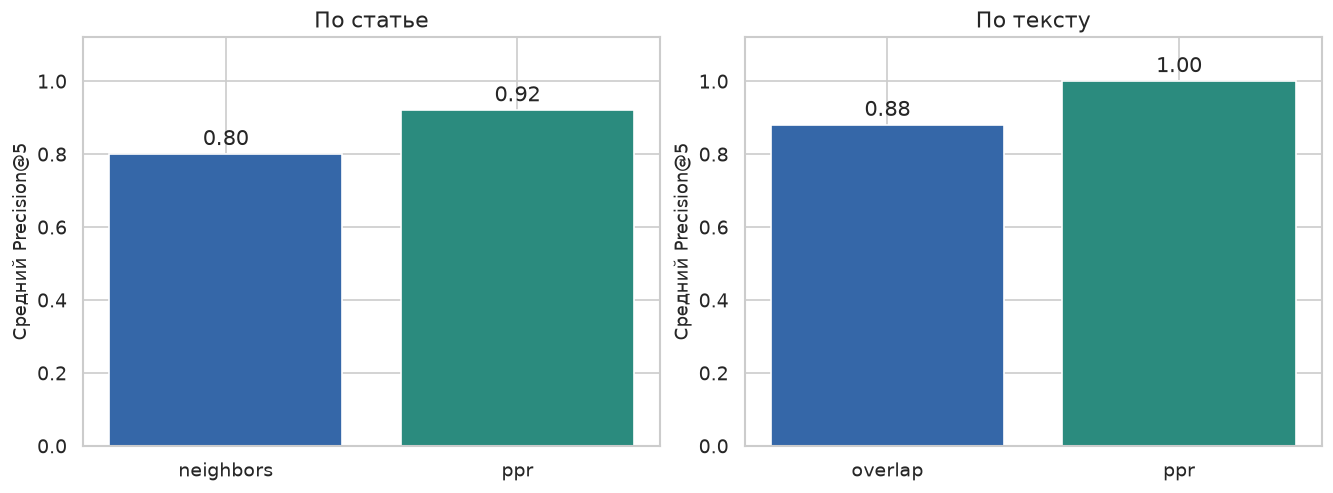

In [24]:
def retrieval_metrics(ranking, judgments, k=5):
    if k < 1:
        raise ValueError('k must be positive')
    if len(set(ranking)) != len(ranking):
        raise ValueError('Duplicate results in ranking')
    top = ranking[:k]
    if any((pid not in judgments for pid in top)):
        raise ValueError('Every evaluated result needs a judgment')
    grades = [judgments[pid] for pid in top]
    if any((g not in (0, 1, 2) for g in judgments.values())):
        raise ValueError('Relevance must be 0, 1 or 2')
    precision = sum((g >= 1 for g in grades)) / k
    dcg = sum(((2 ** g - 1) / math.log2(rank + 1) for rank, g in enumerate(grades, 1)))
    ideal = sorted(judgments.values(), reverse=True)[:k]
    idcg = sum(((2 ** g - 1) / math.log2(rank + 1) for rank, g in enumerate(ideal, 1)))
    return {'precision_at_5': precision, 'pooled_ndcg_at_5': dcg / idcg if idcg else None, 'returned': len(top), 'pool_size': len(judgments)}

def evaluate_queries(engine, queries, judgments):
    results = []
    for query in queries:
        grades = {j['candidate_paper_id']: j['relevance'] for j in judgments if j['query_id'] == query['query_id']}
        methods = ['neighbors', 'ppr'] if query['query_type'] == 'paper' else ['overlap', 'ppr']
        for method in methods:
            response = engine.related(query['paper_id'], method=method) if query['query_type'] == 'paper' else engine.by_text(query['text'], method=method)
            metrics = retrieval_metrics([r['paper_id'] for r in response['results']], grades)
            results.append({'query_id': query['query_id'], 'query_type': query['query_type'], 'method': method, **metrics})
    return results

assert retrieval_metrics(['a','b','c'], {'a':2,'b':1,'c':0}, k=3)['pooled_ndcg_at_5'] == 1.0
assert retrieval_metrics(['c','b','a'], {'a':2,'b':1,'c':0}, k=3)['pooled_ndcg_at_5'] < 1.0
assert retrieval_metrics(['a'], {'a':0})['pooled_ndcg_at_5'] is None
quality = None
if same_corpus:
    evaluation_queries = saved['queries']
    judgments = saved['judgments']
    current_rankings = []
    for query in evaluation_queries:
        pool = {row['candidate_paper_id'] for row in judgments if row['query_id'] == query['query_id']}
        for method in (['neighbors','ppr'] if query['query_type']=='paper' else ['overlap','ppr']):
            response = engine.related(query['paper_id'], method=method) if query['query_type']=='paper' else engine.by_text(query['text'], method=method)
            current_rankings.append(all(row['paper_id'] in pool for row in response['results']))
    if all(current_rankings):
        quality = pd.DataFrame(evaluate_queries(engine, evaluation_queries, judgments))
        show_table(pd.DataFrame(evaluation_queries).fillna(''))
        show_table(quality.round(3))
        show_table(quality.groupby(['query_type','method'])[['precision_at_5','pooled_ndcg_at_5']].mean().round(3))
        show_table(pd.DataFrame(judgments)[['query_id','candidate_paper_id','relevance','rationale']].head(12))
        fig, axes = plt.subplots(1,2,figsize=(11,4),layout='constrained')
        for ax, query_type, label in zip(axes,['paper','text'],['По статье','По тексту']):
            averages = quality[quality['query_type']==query_type].groupby('method')['precision_at_5'].mean()
            ax.bar(averages.index, averages.values, color=['#3567a8','#2b8b7e'])
            ax.set(title=label, ylabel='Средний Precision@5', ylim=(0,1.12))
            for i,value in enumerate(averages.values):
                ax.text(i,value+.025,f'{value:.2f}',ha='center')
        show_figure(fig)
    else:
        print('Выдача изменилась. Для честного сравнения нужно дополнить разметку новых результатов.')
else:
    print('Корпус обновлён. Сначала нужно подготовить оценки для новых статей.')

В сохранённом корпусе средний Precision@5 при поиске по статье составляет 0.80 для
neighbors и 0.92 для PPR. При поиске по теме получено 0.88 для overlap и 1.00 для PPR.
На этих примерах PPR чаще даёт подходящие результаты, но не выигрывает по каждому запросу.
Общие теги иногда связывают разные по смыслу задачи. Малый размер оценки не позволяет
утверждать, что PPR всегда лучше или что он найдёт все нужные статьи.

## 14. Влияние числа тегов

Повторяю построение для 8, 12 и 16 тегов на статью.
В каждом варианте оба графа строятся из одного и того же набора тегов.
Смотрю, как меняются число рёбер, плотность и модулярность.
Больше тегов создаёт больше связей, но вместе с полезными словами может добавить общие.
Разные наборы тегов дают разные графы, поэтому их модулярность
не является прямой оценкой смыслового качества извлечения тегов.

,Максимум тегов,Ключевых слов,Рёбер слов,Рёбер статей,Плотность статей,Сообществ,Модулярность
0,8,2175,13837,3356,0.0269,25,0.5503
1,12,2662,32408,6609,0.0530,22,0.4112
2,16,2882,57976,11724,0.0940,17,0.3229


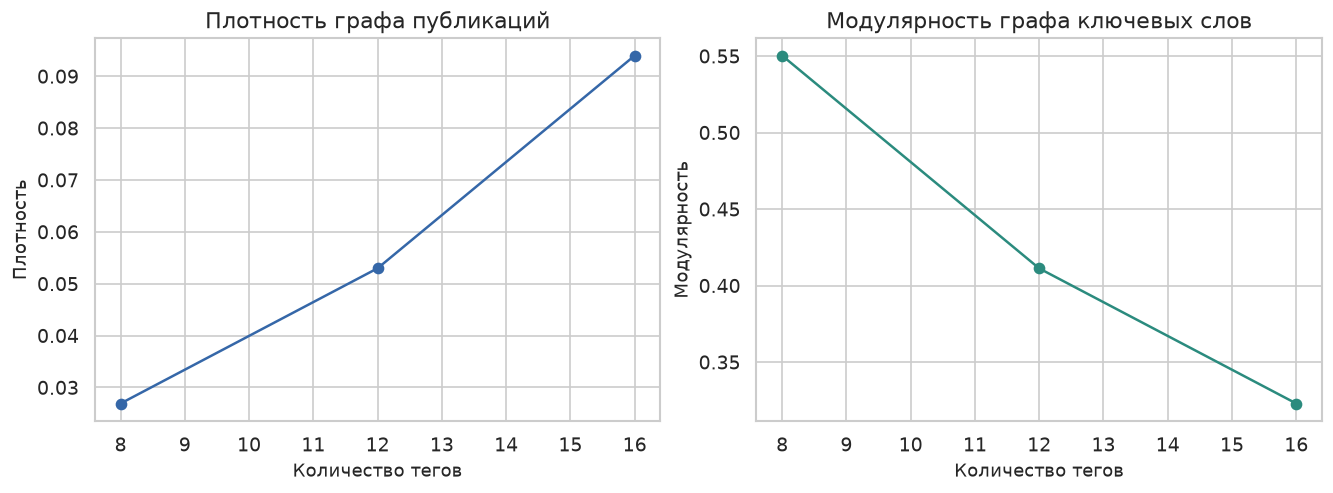

In [25]:
sensitivity_rows = []
for count in cfg['analysis']['keyword_counts']:
    variant = select_keywords(texts, terms, scores, count, cfg['keywords']['phrase_bonus'])
    variant_tg, variant_pg, _, _, _ = build_graphs(papers, variant)
    variant_groups, variant_q = partition(variant_tg, seed=cfg['seed'])
    sensitivity_rows.append({'Максимум тегов': count, 'Ключевых слов': len(variant_tg),
                             'Рёбер слов': variant_tg.number_of_edges(), 'Рёбер статей': variant_pg.number_of_edges(),
                             'Плотность статей': nx.density(variant_pg), 'Сообществ': len(variant_groups),
                             'Модулярность': variant_q})
sensitivity = pd.DataFrame(sensitivity_rows)
show_table(sensitivity.round(4))
fig, axes = plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].plot(sensitivity['Максимум тегов'],sensitivity['Плотность статей'],'o-',color='#3567a8')
axes[0].set(xlabel='Количество тегов',ylabel='Плотность',title='Плотность графа публикаций')
axes[1].plot(sensitivity['Максимум тегов'],sensitivity['Модулярность'],'o-',color='#2b8b7e')
axes[1].set(xlabel='Количество тегов',ylabel='Модулярность',title='Модулярность графа ключевых слов')
show_figure(fig)

## 15. Выводы

В работе собран корпус из 500 уникальных статей с 2020 года.
Названия, авторы и аннотации получены через arXiv API, а исходные ответы сохранены внутри notebook.
После обработки текста выделены отдельные слова и составные ключевые фразы.
Все статьи получили хотя бы один тег.

Граф ключевых слов содержит 2662 узла и 32408 рёбер.
Louvain выделил 22 сообщества, модулярность составила 0.4112.
По ведущим словам и примерам статей видны направления прогнозирования,
моделирования волатильности, торговых решений и оптимизации портфеля.
Некоторые группы смешанные, поэтому их названия являются интерпретацией результата.

По четырём центральностям выделены понятия, которые широко связаны с другими словами
или соединяют разные направления. В этой выборке особенно заметна оптимизация портфеля.

Граф публикаций содержит 500 узлов и 6609 рёбер.
Реализованы поиск прямых соседей, PPR и поиск по текстовому запросу.
Проверки на небольших примерах и на всех парах корпуса подтверждают правильность весов.
Предварительная оценка показывает полезность поиска, но требует расширения разметки.

Основные ограничения: ограниченное число ответов каждого запроса, только названия
и аннотации вместо полных текстов, ошибки автоматического выбора тегов и небольшой
набор оценок поиска. Работа описывает научные публикации и не проверяет прибыльность стратегий.

Все числа в выводах относятся к встроенному снимку и указанным настройкам.
После изменения данных или параметров нужно смотреть новые вычисленные таблицы,
а текстовые выводы и названия групп пересмотреть.

In [26]:
show_table(pd.DataFrame([
    {'Пункт ТЗ': 1, 'Выполнение': 'Выбрана тема финансовых рядов и алгоритмической торговли'},
    {'Пункт ТЗ': 2, 'Выполнение': 'API, названия, авторы, аннотации, не менее 300 статей с 2020 года'},
    {'Пункт ТЗ': 3, 'Выполнение': 'Разведочный анализ, распределения и закон Ципфа'},
    {'Пункт ТЗ': 4, 'Выполнение': 'Нормализация, TF-IDF, фразы из одного, двух и трёх слов'},
    {'Пункт ТЗ': 5, 'Выполнение': 'Граф ключевых слов в NetworkX'},
    {'Пункт ТЗ': 6, 'Выполнение': 'Louvain, модулярность и объяснение всех групп'},
    {'Пункт ТЗ': 7, 'Выполнение': 'Четыре центральности с примерами'},
    {'Пункт ТЗ': 8, 'Выполнение': 'Граф публикаций и поиск по выбранной статье'},
    {'Пункт ТЗ': 9, 'Выполнение': 'Тестовые примеры, проверки корпуса и оценка выдачи'}
]))
print('Расчёт завершён. Статей:', len(papers), 'Сообществ:', len(groups))

,Пункт ТЗ,Выполнение
0,1,Выбрана тема финансовых рядов и алгоритмической торговли
1,2,"API, названия, авторы, аннотации, не менее 300 статей с 2020 года"
2,3,"Разведочный анализ, распределения и закон Ципфа"
3,4,"Нормализация, TF-IDF, фразы из одного, двух и трёх слов"
4,5,Граф ключевых слов в NetworkX
5,6,"Louvain, модулярность и объяснение всех групп"
6,7,Четыре центральности с примерами
7,8,Граф публикаций и поиск по выбранной статье
8,9,"Тестовые примеры, проверки корпуса и оценка выдачи"


Расчёт завершён. Статей: 500 Сообществ: 22
